<a href="https://colab.research.google.com/github/yimarbriceon/ingenieria-conocimiento-uncp/blob/master/Proyecto-final/Proyecto_Cassava_256_Final_(copia).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 Proyecto Final: Pipeline CNN Completo
## 🌿 Diagnóstico de Enfermedades en Hojas de Yuca (Cassava) — Del Problema al Despliegue

**Curso:** IS056B — Ingeniería del Conocimiento
**Docente:** Msc. Jaime Antonio Huaytalla Pariona
**Universidad:** UNCP — Facultad de Ingeniería de Sistemas
**Semestre:** 2026-II | **Unidad:** I — Machine Learning y Redes Neuronales Profundas

**Integrantes:**
| Apellidos y Nombres | Código |
|---|---|
| *HUAYNALAYA ALONZO FRANK ELVIS* | *2024200188F* |
| *BRICEÑO ALAYA YIMAR JESUS* | *2024200181L* |
| *QUINTANILLA CONDOR JUAN JOSUE* | *2024200199D* |
| *GOMEZ MUÑOZ DAVID PEDRO* | *2024200186D* |

---

> 🔄 **Versión 256 px:** todos los modelos (1–4) se entrenaron desde cero con imágenes de **256×256** (una versión anterior usó 192×192). Con más resolución el mejor modelo pasó de F1 macro 0.689 a **0.717** en test.

### 📋 Objetivo
Construir un **pipeline profesional completo de 12 fases** (S05 Arquitecturas CNN, S06 Optimización, S07 Evaluación y Explicabilidad, S08 Producción) para resolver un problema real: **identificar automáticamente la enfermedad presente en una hoja de yuca a partir de una foto tomada con celular**, y desplegar el modelo como un **servicio web (API REST con Flask)** como modelo ligero para móviles (**TFLite**) y como **página web pública** (Hugging Face Spaces, inferencia en el navegador con TensorFlow.js).



---
## ⚙️ Fase 0: Configuración del Entorno

In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import os, json, datetime, platform, logging, shutil, hashlib, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve,
                             auc, roc_auc_score, f1_score, accuracy_score)
from sklearn.preprocessing import label_binarize

# Verificar GPU
print(f"TensorFlow: {tf.__version__}")
print(f"GPU disponible: {tf.config.list_physical_devices('GPU')}")

# Reproducibilidad (Fase 11: semillas fijadas)
SEED = 42
tf.keras.utils.set_random_seed(SEED)   # fija semillas de Python, NumPy y TensorFlow
np.random.seed(SEED)

# Configuración global
IMG_SIZE = (256, 256)   # Las fotos originales son de 800x600. Versión anterior: 192x192.
                        # 256 conserva más detalle de las manchas (CBSD, CGM) con un costo de tiempo moderado.
BATCH_SIZE = 32
NUM_CLASSES = 5         # Cassava: 4 enfermedades + hoja sana

# Estructura del proyecto (Fase 9: versionado)
PROJECT_DIR = '/content/proyecto_cassava'
RAW_DIR = f'{PROJECT_DIR}/data/raw'              # datos crudos tal como vienen de Kaggle
PROCESSED_DIR = f'{PROJECT_DIR}/data/processed_{IMG_SIZE[0]}'  # imágenes redimensionadas y divididas (carpeta propia por tamaño)
for d in [RAW_DIR, PROCESSED_DIR, f'{PROJECT_DIR}/src/models', f'{PROJECT_DIR}/src/training',
          f'{PROJECT_DIR}/experiments', f'{PROJECT_DIR}/models/production']:
    os.makedirs(d, exist_ok=True)
os.chdir(PROJECT_DIR)   # todas las rutas relativas (experiments/, models/) cuelgan de aquí

plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 150
print(f"📁 Directorio del proyecto: {os.getcwd()}")
print("✅ Entorno configurado correctamente")

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
📁 Directorio del proyecto: /content/proyecto_cassava
✅ Entorno configurado correctamente


---
## 📝 Fase 1: Definición del Problema

Antes de escribir código, respondemos las 5 preguntas clave:

### Ficha de Proyecto

| Pregunta | Nuestra Respuesta |
|---|---|
| ¿Qué problema resuelve este modelo? | Diagnóstico temprano de enfermedades de la yuca a partir de una foto de la hoja. Hoy el diagnóstico depende de que un técnico agrícola visite la parcela: es lento, costoso y escaso. Un modelo que clasifique la foto permite actuar antes de que la enfermedad se propague y destruya la cosecha. La yuca es un cultivo de seguridad alimentaria (2.ª fuente de carbohidratos en África) y también se cultiva en la selva peruana. |
| ¿Es clasificación binaria o multiclase? | **Multiclase (5 clases):** Añublo bacteriano (CBB), Rayado marrón (CBSD), Moteado verde (CGM), Mosaico (CMD) y Hoja sana (Healthy). Cada imagen pertenece a una sola clase. |
| ¿Cuál es la métrica principal de éxito? ¿Por qué? | **F1-score macro.** El dataset está muy desbalanceado (CMD tiene más de la mitad de las imágenes): un modelo que siempre diga "CMD" tendría accuracy alta sin servir para nada. El F1 macro promedia el desempeño de las 5 clases por igual, así que castiga ignorar las clases minoritarias. Como métricas secundarias se reportan Accuracy y Macro AUC. |
| ¿Cuáles son las restricciones del proyecto? | Los agricultores usan **celulares de gama baja con poca conectividad**: el modelo final debe pesar **< 10 MB** (versión TFLite para móvil) y responder rápido. Las fotos son de campo (fondos, sombras, varias hojas), no de laboratorio. Además debe exponerse como **API REST** para integrarse con una app o web. Recursos de entrenamiento: GPU T4 gratuita de Colab. |
| ¿Cuál es el baseline (clasificador trivial)? | **Aleatorio:** 1/5 = **20%** de accuracy. **Clase mayoritaria** (siempre "CMD"): ≈ **61%** de accuracy pero F1 macro ≈ 0.15. Nuestro modelo debe superar claramente ambos, sobre todo en F1 macro. |

> 💡 **Fuente del dataset:** *Cassava Leaf Disease Classification* (Kaggle, 2020). 21,397 imágenes recolectadas en Uganda por agricultores con sus celulares y etiquetadas por expertos del National Crops Resources Research Institute (NaCRRI) y el AI Lab de Makerere University. Aunque proviene de Uganda, el añublo bacteriano (CBB) también afecta a la yuca en América Latina, y la metodología es replicable para cultivos de la selva peruana.

---
## 🔍 Fase 2: Selección del Dataset y EDA

**Justificación del dataset** (criterios de la Fase 2):
- ✅ Más de 1,000 imágenes → **21,397**
- ✅ Al menos 3 clases → **5 clases**
- ✅ Aplicación real → diagnóstico agrícola con fotos de celular tomadas en campo

### Descarga desde Kaggle
1. En la página de la competencia (*Cassava Leaf Disease Classification*), pestaña **Rules → "I Understand and Accept"**.
2. En Kaggle: foto de perfil → **Settings → API → Create New Token** → se descarga `kaggle.json`.
3. Ejecutar la celda siguiente y subir `kaggle.json` cuando se abra el selector.

> ⚠️ `kaggle.json` es una credencial personal: **no** la suban a GitHub ni la dejen escrita en el notebook.

In [ ]:
# Configurar la API de Kaggle (token nuevo KGAT_..., guardado en Secretos de Colab)
!pip install -q --upgrade kaggle          # la versión nueva entiende este tipo de token
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

# Prueba rápida de conexión
!kaggle competitions list -s cassava
print("✅ Credenciales de Kaggle listas")

ref                                                                      deadline             category       reward  teamCount  userHasEntered  userRank  
-----------------------------------------------------------------------  -------------------  ---------  ----------  ---------  --------------  --------  
https://www.kaggle.com/competitions/cassava-leaf-disease-classification  2021-02-18 23:59:00  Research   18,000 Usd       3900            True         0  
https://www.kaggle.com/competitions/cassava-disease                      2019-06-01 23:59:00  Community       Kudos         86           False         0  
https://www.kaggle.com/competitions/ammi-2020-convnets                   2020-05-10 23:59:00  Community       Kudos         34           False         0  
https://www.kaggle.com/competitions/ammi-2022-convnets                   2022-04-17 23:00:00  Community       Kudos         21           False         0  
https://www.kaggle.com/competitions/ammi-2023-convnets                

In [ ]:
# Descargar la competencia y descomprimir SOLO lo necesario (train_images + train.csv + mapa de etiquetas)
# El zip completo (~6 GB) incluye las mismas imágenes en TFRecords y un test sin etiquetas que no usaremos.
data_dir = f'{RAW_DIR}/train_images'
zip_path = f'{RAW_DIR}/cassava-leaf-disease-classification.zip'

if os.path.exists(data_dir) and len(os.listdir(data_dir)) > 20000:
    print(f"✅ Dataset ya disponible en {data_dir}")
else:
    print("Descargando desde Kaggle... (puede tardar varios minutos)")
    !kaggle competitions download -c cassava-leaf-disease-classification -p {RAW_DIR}
    if not os.path.exists(zip_path):
        raise RuntimeError("No se descargó el zip. Verifique que aceptó las reglas de la competencia "
                           "en Kaggle (pestaña Rules) y que kaggle.json es correcto.")
    print("Descomprimiendo...")
    !unzip -q -o {zip_path} "train_images/*" train.csv label_num_to_disease_map.json -d {RAW_DIR}
    os.remove(zip_path)   # liberar espacio en disco
    print("✅ Descarga y descompresión completadas")

print(f"Imágenes en train_images: {len(os.listdir(data_dir))}")

Descargando desde Kaggle... (puede tardar varios minutos)
100% 5.76G/5.76G [00:33<00:00, 183MB/s]

Descomprimiendo...
✅ Descarga y descompresión completadas
Imágenes en train_images: 21397


In [ ]:
# Cargar etiquetas
df = pd.read_csv(f'{RAW_DIR}/train.csv')
with open(f'{RAW_DIR}/label_num_to_disease_map.json') as f:
    label_map = {int(k): v for k, v in json.load(f).items()}

# Nombres cortos para gráficos y carpetas (el orden alfabético coincide con las etiquetas 0-4)
CLASS_NAMES = ['CBB', 'CBSD', 'CGM', 'CMD', 'Healthy']
CLASS_DESCRIPTIONS = {
    'CBB':     'Cassava Bacterial Blight — Añublo bacteriano',
    'CBSD':    'Cassava Brown Streak Disease — Rayado marrón (virus)',
    'CGM':     'Cassava Green Mottle — Moteado verde',
    'CMD':     'Cassava Mosaic Disease — Mosaico de la yuca (virus)',
    'Healthy': 'Hoja sana',
}
df['class_name'] = df['label'].map(lambda i: CLASS_NAMES[i])

print("Mapa oficial de etiquetas:")
for k, v in label_map.items():
    print(f"  {k} → {CLASS_NAMES[k]:<8} | {v}")
df.head()

Mapa oficial de etiquetas:
  0 → CBB      | Cassava Bacterial Blight (CBB)
  1 → CBSD     | Cassava Brown Streak Disease (CBSD)
  2 → CGM      | Cassava Green Mottle (CGM)
  3 → CMD      | Cassava Mosaic Disease (CMD)
  4 → Healthy  | Healthy


,image_id,label,class_name
0,1000015157.jpg,0,CBB
1,1000201771.jpg,3,CMD
2,100042118.jpg,1,CBSD
3,1000723321.jpg,1,CBSD
4,1000812911.jpg,3,CMD


### 2.1 Distribución de Clases

Total de clases: 5
Total de imágenes: 21397
Clase más grande: CMD (13158)
Clase más pequeña: CBB (1087)


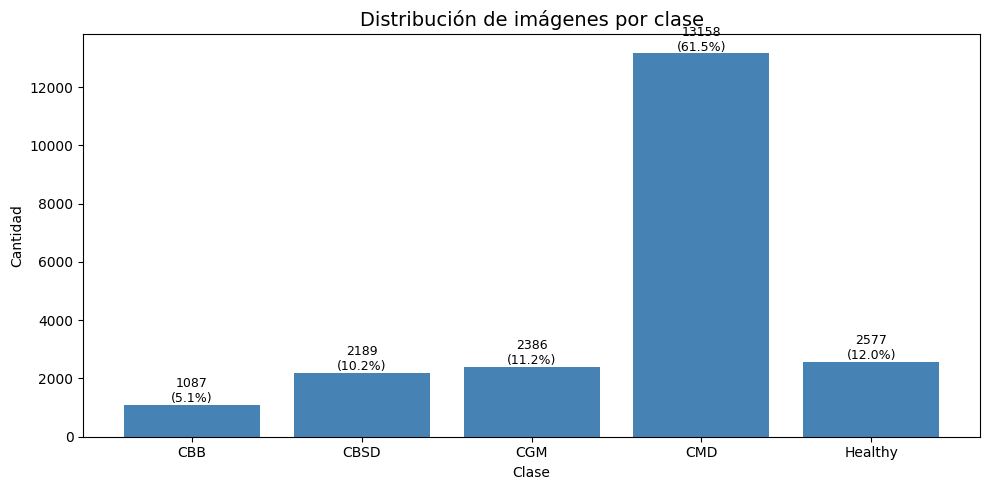


Ratio de desbalance: 12.1:1
Baseline 'clase mayoritaria' (accuracy): 61.5%
Baseline aleatorio (accuracy): 20.0%


In [ ]:
# Contar imágenes por clase
class_counts = df['class_name'].value_counts().reindex(CLASS_NAMES).to_dict()

print(f"Total de clases: {len(class_counts)}")
print(f"Total de imágenes: {sum(class_counts.values())}")
print(f"Clase más grande: {max(class_counts, key=class_counts.get)} ({max(class_counts.values())})")
print(f"Clase más pequeña: {min(class_counts, key=class_counts.get)} ({min(class_counts.values())})")

# Visualizar distribución
plt.figure(figsize=(10, 5))
bars = plt.bar(class_counts.keys(), class_counts.values(), color='steelblue')
for b, v in zip(bars, class_counts.values()):
    plt.text(b.get_x() + b.get_width()/2, v + 100, f"{v}\n({v/sum(class_counts.values()):.1%})",
             ha='center', fontsize=9)
plt.title('Distribución de imágenes por clase', fontsize=14)
plt.xlabel('Clase')
plt.ylabel('Cantidad')
plt.tight_layout()
plt.show()

# Ratio de desbalance
max_c = max(class_counts.values())
min_c = min(class_counts.values())
print(f"\nRatio de desbalance: {max_c/min_c:.1f}:1")
print(f"Baseline 'clase mayoritaria' (accuracy): {max_c/sum(class_counts.values()):.1%}")
print(f"Baseline aleatorio (accuracy): {1/len(class_counts):.1%}")

### 📝 Análisis de la distribución
El dataset está **fuertemente desbalanceado**: CMD concentra **13,158 de 21,397 imágenes (61.5%)**, mientras que CBB solo tiene **1,087 (5.1%)**, un **ratio de 12.1:1**. Por eso la accuracy sola es engañosa: un clasificador que siempre diga "CMD" obtendría **61.5% de accuracy** pero un **F1 macro ≈ 0.15** (F1 = 0.76 en CMD y 0 en las otras 4 clases).

En cuanto a calidad, las imágenes son homogéneas (todas **800×600, RGB**, ≈ 112 KB), con **0 imágenes corruptas** y **0 duplicados exactos**, así que no hubo que descartar ninguna.

Cómo abordamos el desbalance:
1. **División estratificada 70/15/15:** train, val y test conservan la misma proporción de clases (por ejemplo, CBB queda 761 / 163 / 163).
2. **`class_weight` balanceado** en la función de pérdida: CBB = 3.94, CBSD = 1.96, CGM = 1.79, Healthy = 1.66 y CMD = 0.33. Un error en CBB "cuesta" unas 12 veces más que uno en CMD.
3. **F1 macro como métrica principal** y como criterio para elegir el mejor modelo, porque da el mismo peso a las 5 clases.

### 2.2 Propiedades de las Imágenes

In [ ]:
# Analizar propiedades de una muestra de imágenes (50 por clase)
widths, heights, channels, file_sizes = [], [], [], []
for class_name in CLASS_NAMES:
    sample = df[df['class_name'] == class_name].sample(50, random_state=SEED)
    for img_name in sample['image_id']:
        try:
            path = os.path.join(data_dir, img_name)
            img = Image.open(path)
            widths.append(img.width)
            heights.append(img.height)
            channels.append(len(img.getbands()))
            file_sizes.append(os.path.getsize(path) / 1024)
        except Exception:
            pass

print(f"Ancho: [{min(widths)}, {max(widths)}], promedio: {np.mean(widths):.0f}")
print(f"Alto: [{min(heights)}, {max(heights)}], promedio: {np.mean(heights):.0f}")
print(f"Canales: {Counter(channels)}")
print(f"Aspecto promedio: {np.mean(widths)/np.mean(heights):.2f}")
print(f"Peso promedio por archivo: {np.mean(file_sizes):.0f} KB")

Ancho: [800, 800], promedio: 800
Alto: [600, 600], promedio: 600
Canales: Counter({3: 250})
Aspecto promedio: 1.33
Peso promedio por archivo: 112 KB


### 2.3 Visualización de Muestras

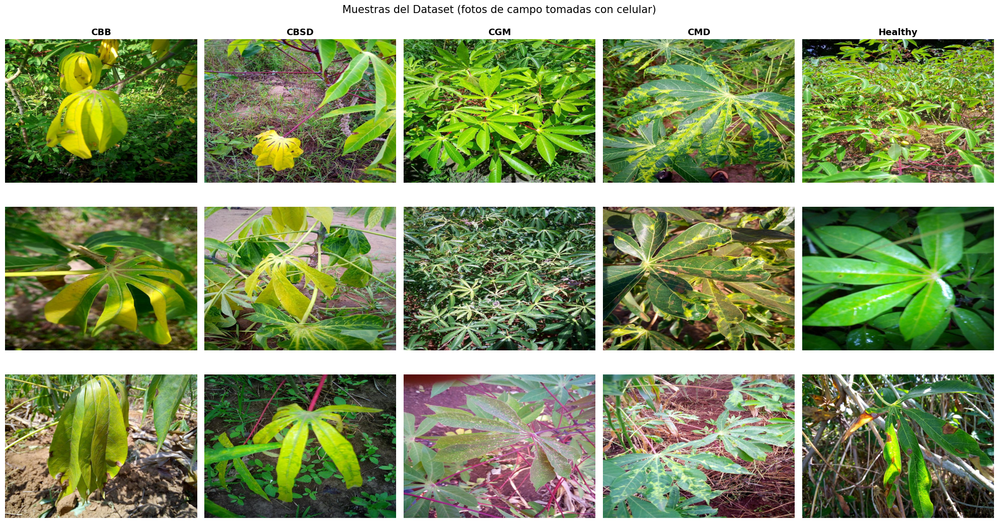

In [ ]:
# Mostrar 3 imágenes por clase
fig, axes = plt.subplots(3, len(CLASS_NAMES), figsize=(20, 11))
for i, class_name in enumerate(CLASS_NAMES):
    imgs = df[df['class_name'] == class_name].sample(3, random_state=SEED)['image_id']
    for j, img_name in enumerate(imgs):
        img = Image.open(os.path.join(data_dir, img_name))
        axes[j, i].imshow(img)
        axes[j, i].set_title(class_name if j == 0 else '', fontsize=13, fontweight='bold')
        axes[j, i].axis('off')

plt.suptitle('Muestras del Dataset (fotos de campo tomadas con celular)', fontsize=15)
plt.tight_layout()
plt.show()

### 2.4 Detección de Imágenes Corruptas

In [ ]:
def find_corrupted_images(directory):
    corrupted = []
    total = 0
    for root, dirs, files in os.walk(directory):
        for fname in files:
            if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue
            fpath = os.path.join(root, fname)
            total += 1
            try:
                img = Image.open(fpath)
                img.verify()
            except Exception as e:
                corrupted.append((fpath, str(e)))
    return corrupted, total

corrupted, total = find_corrupted_images(data_dir)
print(f"Imágenes analizadas: {total}")
print(f"Imágenes corruptas: {len(corrupted)} ({len(corrupted)/total*100:.2f}%)")
if corrupted:
    for path, err in corrupted[:5]:
        print(f"  ❌ {path}: {err}")

# Excluir corruptas del DataFrame para no usarlas en el entrenamiento
corrupted_names = {os.path.basename(p) for p, _ in corrupted}
df = df[~df['image_id'].isin(corrupted_names)].reset_index(drop=True)
print(f"Imágenes válidas: {len(df)}")

Imágenes analizadas: 21397
Imágenes corruptas: 0 (0.00%)
Imágenes válidas: 21397


### 2.5 Detección de Duplicados
Si una misma imagen aparece en train y en test, el modelo "hace trampa" (data leakage). Buscamos duplicados exactos con un hash MD5 de cada archivo.

In [ ]:
def file_md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

with ThreadPoolExecutor(max_workers=8) as ex:
    df['md5'] = list(ex.map(file_md5, [os.path.join(data_dir, n) for n in df['image_id']]))

dup_mask = df.duplicated('md5', keep='first')
print(f"Duplicados exactos encontrados: {dup_mask.sum()}")
if dup_mask.any():
    conflictos = df[df.duplicated('md5', keep=False)].groupby('md5')['label'].nunique()
    print(f"  De ellos, con etiquetas distintas: {(conflictos > 1).sum()}")
    df = df[~dup_mask].reset_index(drop=True)   # conservar una sola copia
print(f"Imágenes finales para el pipeline: {len(df)}")

Duplicados exactos encontrados: 0
Imágenes finales para el pipeline: 21397


---
## 🔄 Fase 3: Preprocesamiento y Data Augmentation

### 3.0 División estratificada y redimensionado
Las fotos originales pesan bastante (800×600). Las **redimensionamos una sola vez** a `IMG_SIZE` y las guardamos en carpetas por clase (`train/`, `val/`, `test/`). Así:
- Cada época lee archivos pequeños → el entrenamiento es mucho más rápido.
- Podemos usar `image_dataset_from_directory` igual que en el ejemplo.

**División 70 / 15 / 15 estratificada:** cada subconjunto conserva la misma proporción de clases. El conjunto de **test no se toca** hasta la evaluación final (Fase 6). El test oficial de Kaggle está oculto, por eso creamos el nuestro.

In [ ]:
# División estratificada 70/15/15
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)

split_summary = pd.DataFrame({
    'train': train_df['class_name'].value_counts(),
    'val':   val_df['class_name'].value_counts(),
    'test':  test_df['class_name'].value_counts(),
}).reindex(CLASS_NAMES)
split_summary.loc['TOTAL'] = split_summary.sum()
print(split_summary)

def resize_and_save(args):
    src, dst = args
    if os.path.exists(dst):
        return
    img = Image.open(src).convert('RGB').resize(IMG_SIZE, Image.BILINEAR)
    img.save(dst, quality=95)

def build_split(split_df, split_name):
    tasks = []
    for name, cls in zip(split_df['image_id'], split_df['class_name']):
        out_dir = os.path.join(PROCESSED_DIR, split_name, cls)
        os.makedirs(out_dir, exist_ok=True)
        tasks.append((os.path.join(data_dir, name), os.path.join(out_dir, name)))
    with ThreadPoolExecutor(max_workers=8) as ex:
        list(ex.map(resize_and_save, tasks))
    print(f"  ✅ {split_name}: {len(tasks)} imágenes")

print(f"\nRedimensionando a {IMG_SIZE} y guardando en {PROCESSED_DIR} ...")
for split_df, split_name in [(train_df, 'train'), (val_df, 'val'), (test_df, 'test')]:
    build_split(split_df, split_name)

            train   val  test
class_name                   
CBB           761   163   163
CBSD         1532   328   329
CGM          1670   358   358
CMD          9210  1974  1974
Healthy      1804   387   386
TOTAL       14977  3210  3210

Redimensionando a (256, 256) y guardando en /content/proyecto_cassava/data/processed_256 ...
  ✅ train: 14977 imágenes
  ✅ val: 3210 imágenes
  ✅ test: 3210 imágenes


### 3.1 Pipeline con `tf.data`

In [ ]:
# Pipeline con tf.data (recomendado)
train_dataset = tf.keras.utils.image_dataset_from_directory(
    f'{PROCESSED_DIR}/train', image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    seed=SEED, shuffle=True, label_mode='categorical', class_names=CLASS_NAMES
)
val_dataset = tf.keras.utils.image_dataset_from_directory(
    f'{PROCESSED_DIR}/val', image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    shuffle=False, label_mode='categorical', class_names=CLASS_NAMES
)
test_dataset = tf.keras.utils.image_dataset_from_directory(
    f'{PROCESSED_DIR}/test', image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    shuffle=False, label_mode='categorical', class_names=CLASS_NAMES
)

class_names = train_dataset.class_names
NUM_CLASSES = len(class_names)
test_file_paths = test_dataset.file_paths   # para mostrar imágenes en el análisis de errores
print(f"Clases: {NUM_CLASSES} → {class_names}")

Found 14977 files belonging to 5 classes.
Found 3210 files belonging to 5 classes.
Found 3210 files belonging to 5 classes.
Clases: 5 → ['CBB', 'CBSD', 'CGM', 'CMD', 'Healthy']


In [ ]:
# Capas de augmentation y normalización
normalization = tf.keras.layers.Rescaling(1./255)

# Justificación de cada transformación (Guía Estratégica de Data Augmentation):
#  - Flip horizontal y vertical: una hoja fotografiada desde arriba no tiene "arriba" ni "abajo" fijo.
#  - Rotación: las hojas rotan naturalmente en la planta y en la foto.
#  - Zoom: cada agricultor toma la foto a una distancia distinta.
#  - Brillo / contraste: fotos de exterior con sol, sombra o nubes.
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomBrightness(0.15),   # trabaja sobre píxeles en rango [0, 255]
    tf.keras.layers.RandomContrast(0.15),
], name='data_augmentation')

# Aplicar al dataset (augmentation primero, sobre [0,255]; luego normalización a [0,1])
def preprocess_train(images, labels):
    images = data_augmentation(images, training=True)
    images = normalization(images)
    return images, labels

def preprocess_val(images, labels):
    images = normalization(images)
    return images, labels

# ⚠️ IMPORTANTE: Augmentation SOLO en entrenamiento
train_ds = train_dataset.map(preprocess_train, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.shuffle(100).prefetch(tf.data.AUTOTUNE)

# Versión de train SIN augmentation: para el Modelo 3, que ya trae augmentation dentro
# (así evitamos aplicar augmentation dos veces)
train_ds_noaug = train_dataset.map(preprocess_val, num_parallel_calls=tf.data.AUTOTUNE)
train_ds_noaug = train_ds_noaug.shuffle(100).prefetch(tf.data.AUTOTUNE)

val_ds = val_dataset.map(preprocess_val, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

test_ds = test_dataset.map(preprocess_val, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("✅ Pipelines de datos configurados")
print(f"  Train: CON augmentation (Modelos 1 y 2) / SIN augmentation externa (Modelo 3)")
print(f"  Val:   SIN augmentation")
print(f"  Test:  SIN augmentation (solo se usa en la Fase 6)")

✅ Pipelines de datos configurados
  Train: CON augmentation (Modelos 1 y 2) / SIN augmentation externa (Modelo 3)
  Val:   SIN augmentation
  Test:  SIN augmentation (solo se usa en la Fase 6)


In [ ]:
# Pesos de clase para compensar el desbalance (clases pequeñas pesan más en la loss)
class_weights_arr = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_df['label'].values)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(class_weights_arr)}
for i, w in CLASS_WEIGHT.items():
    print(f"  {class_names[i]:<8}: peso = {w:.3f}")

  CBB     : peso = 3.936
  CBSD    : peso = 1.955
  CGM     : peso = 1.794
  CMD     : peso = 0.325
  Healthy : peso = 1.660


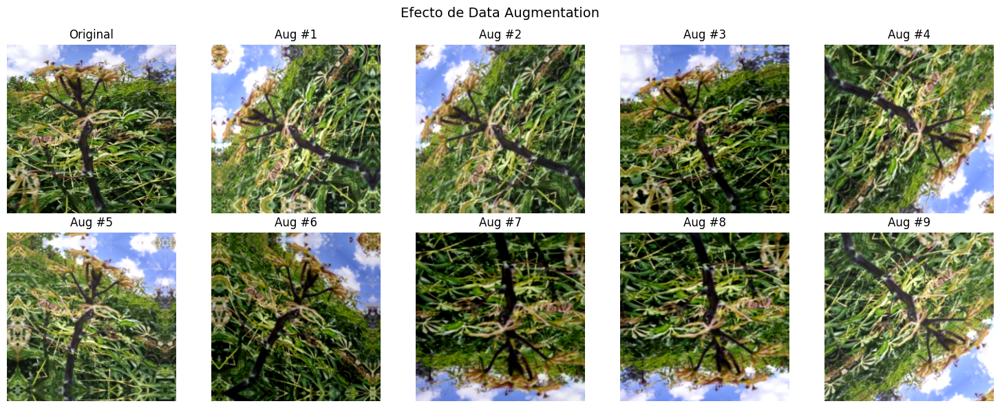

In [ ]:
# Visualizar augmentation
sample_batch = next(iter(train_dataset))
sample_img = sample_batch[0][0:1]  # Primera imagen, sin normalizar

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes[0, 0].imshow(sample_img[0].numpy().astype('uint8'))
axes[0, 0].set_title('Original')
axes[0, 0].axis('off')

for i in range(1, 10):
    row, col = i // 5, i % 5
    augmented = data_augmentation(sample_img, training=True)
    axes[row, col].imshow(np.clip(augmented[0].numpy(), 0, 255).astype('uint8'))
    axes[row, col].set_title(f'Aug #{i}')
    axes[row, col].axis('off')

plt.suptitle('Efecto de Data Augmentation', fontsize=14)
plt.tight_layout()
plt.show()

---
## 🏗️ Fase 4: Diseño de 4 Modelos (3 CNN propias + Transfer Learning)

### Modelo 1: CNN Baseline
Arquitectura simple con 3 bloques Conv+BN+ReLU+MaxPool. **Propósito:** confirmar que el pipeline funciona de principio a fin antes de invertir en arquitecturas complejas.

In [ ]:
def build_baseline_model(input_shape, num_classes):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        # Bloque 1
        tf.keras.layers.Conv2D(32, (3,3), padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.MaxPooling2D((2,2)),
        # Bloque 2
        tf.keras.layers.Conv2D(64, (3,3), padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.MaxPooling2D((2,2)),
        # Bloque 3
        tf.keras.layers.Conv2D(128, (3,3), padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation('relu'),
        tf.keras.layers.GlobalAveragePooling2D(),
        # Clasificador
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(num_classes, activation='softmax')
    ], name='cnn_baseline')
    return model

model_baseline = build_baseline_model((*IMG_SIZE, 3), NUM_CLASSES)
model_baseline.summary()

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 128,453 (501.77 KB)

 Trainable params: 128,005 (500.02 KB)

 Non-trainable params: 448 (1.75 KB)

### Modelo 2: CNN Mejorada con Bloques Residuales
Aplica skip connections (S05) con Functional API para combatir el desvanecimiento del gradiente.

In [ ]:
def residual_block(x, filters, stride=1):
    shortcut = x
    # Rama principal
    x = tf.keras.layers.Conv2D(filters, (3,3), strides=stride, padding='same')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Conv2D(filters, (3,3), padding='same')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    # Ajustar shortcut si cambian dimensiones
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = tf.keras.layers.Conv2D(filters, (1,1), strides=stride, padding='same')(shortcut)
        shortcut = tf.keras.layers.BatchNormalization()(shortcut)
    x = tf.keras.layers.Add()([x, shortcut])
    x = tf.keras.layers.Activation('relu')(x)
    return x

def build_improved_model(input_shape, num_classes):
    inputs = tf.keras.layers.Input(shape=input_shape)
    # Stem
    x = tf.keras.layers.Conv2D(64, (7,7), strides=2, padding='same')(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling2D((3,3), strides=2, padding='same')(x)
    # Bloques residuales
    x = residual_block(x, 64)
    x = residual_block(x, 64)
    x = residual_block(x, 128, stride=2)
    x = residual_block(x, 128)
    x = residual_block(x, 256, stride=2)
    x = residual_block(x, 256)
    # Clasificador
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(512, kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name='cnn_improved')

model_improved = build_improved_model((*IMG_SIZE, 3), NUM_CLASSES)
model_improved.summary()

Model: "cnn_improved"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      9,472 │ input_layer_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 64, 64,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     36,928 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     36,928 │ activation_4[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 64, 64,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │     36,928 │ activation_5[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 64, 64,    │     36,928 │ activation_6[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_7[0][0]  

 Total params: 2,925,701 (11.16 MB)

 Trainable params: 2,920,197 (11.14 MB)

 Non-trainable params: 5,504 (21.50 KB)

### Modelo 3: CNN Optimizada
Augmentation integrado en el grafo + stem con stride agresivo + regularización L2 + doble dropout (S06).

In [ ]:
def build_optimized_model(input_shape, num_classes):
    inputs = tf.keras.layers.Input(shape=input_shape)
    # Augmentation dentro del modelo (solo activo en training; recibe imágenes ya normalizadas en [0,1])
    x = tf.keras.layers.RandomFlip("horizontal_and_vertical")(inputs)
    x = tf.keras.layers.RandomRotation(0.15)(x)
    x = tf.keras.layers.RandomZoom(0.15)(x)
    x = tf.keras.layers.RandomContrast(0.15)(x)
    # Stem con L2
    x = tf.keras.layers.Conv2D(64, (7,7), strides=2, padding='same',
                               kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling2D((3,3), strides=2, padding='same')(x)
    # Bloques residuales
    for filters in [64, 64, 128, 128, 256, 256]:
        stride = 2 if (filters != 64 and x.shape[-1] != filters) else 1
        x = residual_block(x, filters, stride)
    # Clasificador con doble dropout
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(512, kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    x = tf.keras.layers.Dense(256, kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name='cnn_optimized')

model_optimized = build_optimized_model((*IMG_SIZE, 3), NUM_CLASSES)
model_optimized.summary()

Model: "cnn_optimized"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_1       │ (None, 256, 256,  │          0 │ input_layer_3[0]… │
│ (RandomFlip)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation_1   │ (None, 256, 256,  │          0 │ random_flip_1[0]… │
│ (RandomRotation)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom_1       │ (None, 256, 256,  │          0 │ random_rotation_… │
│ (RandomZoom)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_contrast_1   │ (None, 256, 256,  │          0 │ random_zoom_1[0]… │
│ (RandomContrast)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 128, 128,  │      9,472 │ random_contrast_… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_18[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_17       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 64, 64,    │          0 │ activation_17[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 64, 64,    │     36,928 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_19[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_18       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 64, 64,    │     36,928 │ activation_18[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_20[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_19       │ (None, 64, 64,    │          0 │ add_6[0][0]       │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 64, 64,    │     36,928 │ activation_19[0]

 Total params: 3,055,749 (11.66 MB)

 Trainable params: 3,050,245 (11.64 MB)

 Non-trainable params: 5,504 (21.50 KB)

### Modelo 4: Transfer Learning con EfficientNetB0
Los modelos 1–3 se entrenan **desde cero**. El Modelo 4 parte de **EfficientNetB0 preentrenada en ImageNet** (1.2 millones de imágenes): sus capas ya saben detectar bordes, texturas y formas, y solo hay que **adaptarlas** a las hojas de yuca. Es la técnica más efectiva cuando el dataset es pequeño o difícil.

Se entrena en **dos fases**:
1. **Cabeza (head):** la base preentrenada queda **congelada** y solo se entrena el clasificador nuevo (lr = 1e-3).
2. **Fine-tuning:** se **descongela** la base (excepto BatchNormalization) y se ajusta todo con un learning rate **10 veces menor** (1e-4) para no destruir lo aprendido en ImageNet.

> EfficientNet espera píxeles en [0, 255]: como nuestro pipeline entrega [0, 1], la primera capa los multiplica por 255.

In [ ]:
def build_transfer_model(input_shape, num_classes):
    base = tf.keras.applications.EfficientNetB0(include_top=False, weights='imagenet',
                                                input_shape=input_shape)
    base.trainable = False                                   # Fase 1: base congelada
    inputs = tf.keras.layers.Input(shape=input_shape)
    x = tf.keras.layers.Rescaling(255.0)(inputs)             # [0,1] → [0,255] (lo que espera EfficientNet)
    x = base(x, training=False)                              # BatchNorm de la base siempre en modo inferencia
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name='transfer_efficientnetb0'), base

model_transfer, base_transfer = build_transfer_model((*IMG_SIZE, 3), NUM_CLASSES)
print(f"Parámetros totales: {model_transfer.count_params():,} | "
      f"entrenables en la fase 1: {sum(np.prod(v.shape) for v in model_transfer.trainable_weights):,}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Parámetros totales: 4,055,976 | entrenables en la fase 1: 6,405


In [ ]:
# Comparar los 4 modelos
print(f"{'Modelo':<25} {'Params':>12} {'Tamaño (MB)':>12}")
print("-" * 50)
for name, m in [("CNN Baseline", model_baseline),
                ("CNN Mejorada", model_improved),
                ("CNN Optimizada", model_optimized),
                ("Transfer EfficientNetB0", model_transfer)]:
    params = m.count_params()
    size_mb = params * 4 / 1024 / 1024
    print(f"{name:<25} {params:>12,} {size_mb:>10.1f} MB")

Modelo                          Params  Tamaño (MB)
--------------------------------------------------
CNN Baseline                   128,453        0.5 MB
CNN Mejorada                 2,925,701       11.2 MB
CNN Optimizada               3,055,749       11.7 MB
Transfer EfficientNetB0      4,055,976       15.5 MB


---
## 🏋️ Fase 5: Entrenamiento con Callbacks Profesionales

Entrenaremos los 4 modelos para comparar. Empezamos con el Baseline.

Además de los **5 callbacks profesionales** (ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, TensorBoard, CSVLogger) agregamos un **callback personalizado `ExperimentLogger`** que deja un registro permanente en `experiment.log` (ver Fase 10).

> ⏱️ En esta ejecución (256 px, GPU de Colab) los tiempos fueron: Baseline 19 min, Mejorada 36 min, Optimizada 43 min y Transfer Learning 30 min (cabeza 7 + fine-tuning 23). EarlyStopping detiene el entrenamiento antes si ya no mejora. Si Colab se desconecta, los mejores pesos quedan guardados en `experiments/checkpoints/`.

In [ ]:
# Configuración centralizada (Panel de Control)
CONFIG = {
    'learning_rate': 1e-3,
    'epochs': 50,
    'batch_size': BATCH_SIZE,
    'img_size': list(IMG_SIZE),
    'optimizer': 'adam',
    'weight_decay': 1e-4,
    'label_smoothing': 0.1,
    'use_class_weight': True,     # compensar desbalance
    'seed': SEED,
}

# Fase 10: callback personalizado de logging
class ExperimentLogger(tf.keras.callbacks.Callback):
    # Escribe una línea por época en experiment.log (huella inmutable del experimento)
    def __init__(self, log_path, experiment_name):
        super().__init__()
        self.experiment_name = experiment_name
        self.logger = logging.getLogger(experiment_name)
        self.logger.setLevel(logging.INFO)
        self.logger.handlers.clear()
        handler = logging.FileHandler(log_path, encoding='utf-8')
        handler.setFormatter(logging.Formatter('[%(asctime)s] %(levelname)s: %(message)s',
                                               datefmt='%Y-%m-%d %H:%M:%S'))
        self.logger.addHandler(handler)

    def on_train_begin(self, logs=None):
        self.start = time.time()
        self.logger.info(f'Inicio del experimento {self.experiment_name} | '
                         f'params={self.model.count_params():,}')

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        self.logger.info(
            f'Época {epoch+1}: '
            f'loss={logs.get("loss", 0):.4f}, acc={logs.get("accuracy", 0):.4f}, '
            f'val_loss={logs.get("val_loss", 0):.4f}, val_acc={logs.get("val_accuracy", 0):.4f}, '
            f'val_f1_macro={logs.get("val_f1_macro", 0):.4f}'
        )

    def on_train_end(self, logs=None):
        self.logger.info(f'Fin del entrenamiento | duración={(time.time()-self.start)/60:.1f} min')


def train_model(model, train_ds, val_ds, config, experiment_name, class_weight=None):
    # Entrena un modelo con configuración profesional
    log_dir = f"experiments/logs/{experiment_name}"
    checkpoint_dir = f"experiments/checkpoints/{experiment_name}"
    os.makedirs(log_dir, exist_ok=True)
    os.makedirs(checkpoint_dir, exist_ok=True)

    # Guardar configuración
    with open(f"{log_dir}/config.json", 'w') as f:
        json.dump(config, f, indent=2)

    # Compilar
    optimizer = tf.keras.optimizers.Adam(
        learning_rate=config['learning_rate'],
        weight_decay=config['weight_decay']
    )
    loss_fn = tf.keras.losses.CategoricalCrossentropy(
        label_smoothing=config['label_smoothing']
    )
    model.compile(optimizer=optimizer, loss=loss_fn,
                  metrics=['accuracy',
                           tf.keras.metrics.AUC(name='auc'),
                           tf.keras.metrics.F1Score(average='macro', name='f1_macro')])

    # Callbacks
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            f"{checkpoint_dir}/best_model.keras",
            monitor='val_f1_macro', mode='max', save_best_only=True, verbose=1),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=15, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
        tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1),
        tf.keras.callbacks.CSVLogger(f"{log_dir}/training_log.csv"),
        ExperimentLogger(f"{log_dir}/experiment.log", experiment_name),
    ]

    # Entrenar
    history = model.fit(train_ds, validation_data=val_ds,
                        epochs=config['epochs'], callbacks=callbacks,
                        class_weight=class_weight if config['use_class_weight'] else None,
                        verbose=1)
    return history, log_dir, checkpoint_dir

class HistoriaCombinada:
    # Une los historiales de varias fases de entrenamiento (ej. head + fine-tuning) en uno solo
    def __init__(self, *historias):
        claves = set.intersection(*[set(h.history) for h in historias])
        self.history = {k: sum((list(h.history[k]) for h in historias), []) for k in claves}

print("✅ Función de entrenamiento definida")

✅ Función de entrenamiento definida


### ♻️ ¿Sesión nueva? Restaurar los modelos ya entrenados
Colab borra todo al cerrar la sesión. Si ya existe un respaldo (`experimentos.zip`, ver celda de respaldo más abajo):
1. Cambiar `RESTAURAR = True` en la celda siguiente.
2. Ejecutar el notebook normalmente: esta celda carga los modelos del respaldo y las celdas de entrenamiento **se saltan solas** los que ya están restaurados (solo entrena los que falten, por ejemplo el Modelo 4).

Con `RESTAURAR = False` (valor por defecto) se entrenan todos los modelos desde cero.

> ⚠️ **Versión 256 px:** `RESTAURAR = False` para entrenar los 4 modelos desde cero. Los respaldos anteriores (192 px) **no sirven**: el notebook los rechaza si se intentan cargar. Si la sesión se corta a mitad del entrenamiento, ejecuten la celda de respaldo después de cada modelo terminado y, en la sesión nueva, pongan `RESTAURAR = True` con ese zip.


In [ ]:
RESTAURAR = False  # ← True en una sesión nueva para NO volver a entrenar lo que ya está en el respaldo

import glob
timestamp = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')

class HistoryFromCSV:
    # Reconstruye history.history a partir del archivo del CSVLogger
    def __init__(self, csv_path):
        self.history = pd.read_csv(csv_path).drop(columns=['epoch']).to_dict('list')

def restaurar(prefijo):
    log_dir = sorted(glob.glob(f'experiments/logs/{prefijo}_*'))[-1]   # el experimento más reciente
    ckpt_dir = log_dir.replace('/logs/', '/checkpoints/')
    modelo = tf.keras.models.load_model(f'{ckpt_dir}/best_model.keras')
    if tuple(modelo.input_shape[1:3]) != tuple(IMG_SIZE):
        raise ValueError(f"El respaldo de {prefijo} es de {modelo.input_shape[1]} px y IMG_SIZE es {IMG_SIZE[0]} px. "
                         "Use un experimentos.zip generado con esta misma resolución.")
    print(f'✅ {prefijo}: restaurado desde {ckpt_dir}')
    return modelo, HistoryFromCSV(f'{log_dir}/training_log.csv'), log_dir, ckpt_dir

def hay_respaldo(prefijo):
    return len(glob.glob(f'experiments/checkpoints/{prefijo}_*/best_model.keras')) > 0

if RESTAURAR:
    zip_drive = '/content/drive/MyDrive/proyecto_cassava/experimentos.zip'
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        assert os.path.exists(zip_drive)
        zip_local = zip_drive
    except Exception:
        from google.colab import files
        print("No se encontró el respaldo en Drive. Suba experimentos.zip:")
        zip_local = list(files.upload().keys())[0]
    !unzip -q -o "{zip_local}" -d {PROJECT_DIR}

    if hay_respaldo('baseline'):
        model_baseline, history_baseline, log_baseline, ckpt_baseline = restaurar('baseline')
    if hay_respaldo('improved'):
        model_improved, history_improved, log_improved, ckpt_improved = restaurar('improved')
    if hay_respaldo('optimized'):
        model_optimized, history_optimized, log_optimized, ckpt_optimized = restaurar('optimized')
    if hay_respaldo('transfer_ft'):
        model_transfer, h_ft, log_transfer, ckpt_transfer = restaurar('transfer_ft')
        history_transfer = HistoriaCombinada(
            HistoryFromCSV(sorted(glob.glob('experiments/logs/transfer_head_*'))[-1] + '/training_log.csv'), h_ft)
    faltan = [n for n, v in [('Modelo 1', 'history_baseline'), ('Modelo 2', 'history_improved'),
                             ('Modelo 3', 'history_optimized'), ('Modelo 4', 'history_transfer')]
              if v not in globals()]
    print("Se entrenarán:", ', '.join(faltan) if faltan else "ninguno (todo restaurado)")
else:
    print("RESTAURAR = False → se entrenan todos los modelos en esta sesión")

RESTAURAR = False → se entrenan todos los modelos en esta sesión


In [ ]:
# Entrenar Modelo 1: Baseline
if RESTAURAR and 'history_baseline' in globals():
    print('✅ Modelo 1 restaurado del respaldo: no se vuelve a entrenar')
else:
    history_baseline, log_baseline, ckpt_baseline = train_model(
        model_baseline, train_ds, val_ds, CONFIG, f"baseline_{timestamp}", CLASS_WEIGHT
    )

INFO:baseline_20261108_214948:Inicio del experimento baseline_20261108_214948 | params=128,453


Epoch 1/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.3380 - auc: 0.6407 - f1_macro: 0.2425 - loss: 1.5743
Epoch 1: val_f1_macro improved from None to 0.27508, saving model to experiments/checkpoints/baseline_20261108_214948/best_model.keras

Epoch 1: finished saving model to experiments/checkpoints/baseline_20261108_214948/best_model.keras


INFO:baseline_20261108_214948:Época 1: loss=1.5416, acc=0.3819, val_loss=1.5743, val_acc=0.3847, val_f1_macro=0.2751


469/469 ━━━━━━━━━━━━━━━━━━━━ 72s 97ms/step - accuracy: 0.3819 - auc: 0.6835 - f1_macro: 0.2781 - loss: 1.5416 - val_accuracy: 0.3847 - val_auc: 0.6122 - val_f1_macro: 0.2751 - val_loss: 1.5743 - learning_rate: 0.0010
Epoch 2/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.4507 - auc: 0.7492 - f1_macro: 0.3200 - loss: 1.4648
Epoch 2: val_f1_macro did not improve from 0.27508


INFO:baseline_20261108_214948:Época 2: loss=1.4674, acc=0.4570, val_loss=1.6737, val_acc=0.2860, val_f1_macro=0.2109


469/469 ━━━━━━━━━━━━━━━━━━━━ 42s 73ms/step - accuracy: 0.4570 - auc: 0.7512 - f1_macro: 0.3277 - loss: 1.4674 - val_accuracy: 0.2860 - val_auc: 0.5328 - val_f1_macro: 0.2109 - val_loss: 1.6737 - learning_rate: 0.0010
Epoch 3/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.4880 - auc: 0.7812 - f1_macro: 0.3528 - loss: 1.4518
Epoch 3: val_f1_macro improved from 0.27508 to 0.31554, saving model to experiments/checkpoints/baseline_20261108_214948/best_model.keras

Epoch 3: finished saving model to experiments/checkpoints/baseline_20261108_214948/best_model.keras


... (45 outputs left out)

469/469 ━━━━━━━━━━━━━━━━━━━━ 43s 74ms/step - accuracy: 0.6498 - auc: 0.8874 - f1_macro: 0.5267 - loss: 1.1746 - val_accuracy: 0.3838 - val_auc: 0.6866 - val_f1_macro: 0.3931 - val_loss: 1.5932 - learning_rate: 1.2500e-04
Epoch 26/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.6514 - auc: 0.8891 - f1_macro: 0.5302 - loss: 1.1720
Epoch 26: val_f1_macro did not improve from 0.48690

Epoch 26: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.


INFO:baseline_20261108_214948:Época 26: loss=1.1708, acc=0.6535, val_loss=1.3747, val_acc=0.4903, val_f1_macro=0.4357


469/469 ━━━━━━━━━━━━━━━━━━━━ 43s 74ms/step - accuracy: 0.6535 - auc: 0.8889 - f1_macro: 0.5325 - loss: 1.1708 - val_accuracy: 0.4903 - val_auc: 0.7719 - val_f1_macro: 0.4357 - val_loss: 1.3747 - learning_rate: 1.2500e-04
Epoch 26: early stopping
Restoring model weights from the end of the best epoch: 11.


INFO:baseline_20261108_214948:Fin del entrenamiento | duración=18.9 min


In [ ]:
# Entrenar Modelo 2: Mejorada
if RESTAURAR and 'history_improved' in globals():
    print('✅ Modelo 2 restaurado del respaldo: no se vuelve a entrenar')
else:
    history_improved, log_improved, ckpt_improved = train_model(
        model_improved, train_ds, val_ds, CONFIG, f"improved_{timestamp}", CLASS_WEIGHT
    )

INFO:improved_20261108_214948:Inicio del experimento improved_20261108_214948 | params=2,925,701


Epoch 1/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.2898 - auc: 0.6022 - f1_macro: 0.2128 - loss: 1.8893
Epoch 1: val_f1_macro improved from None to 0.13661, saving model to experiments/checkpoints/improved_20261108_214948/best_model.keras

Epoch 1: finished saving model to experiments/checkpoints/improved_20261108_214948/best_model.keras


INFO:improved_20261108_214948:Época 1: loss=1.7823, acc=0.3068, val_loss=1.7948, val_acc=0.2639, val_f1_macro=0.1366


469/469 ━━━━━━━━━━━━━━━━━━━━ 92s 118ms/step - accuracy: 0.3068 - auc: 0.6194 - f1_macro: 0.2289 - loss: 1.7823 - val_accuracy: 0.2639 - val_auc: 0.5401 - val_f1_macro: 0.1366 - val_loss: 1.7948 - learning_rate: 0.0010
Epoch 2/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.3502 - auc: 0.6801 - f1_macro: 0.2633 - loss: 1.6359
Epoch 2: val_f1_macro improved from 0.13661 to 0.31568, saving model to experiments/checkpoints/improved_20261108_214948/best_model.keras

Epoch 2: finished saving model to experiments/checkpoints/improved_20261108_214948/best_model.keras


INFO:improved_20261108_214948:Época 2: loss=1.6300, acc=0.3578, val_loss=1.5499, val_acc=0.5688, val_f1_macro=0.3157


469/469 ━━━━━━━━━━━━━━━━━━━━ 43s 76ms/step - accuracy: 0.3578 - auc: 0.6774 - f1_macro: 0.2670 - loss: 1.6300 - val_accuracy: 0.5688 - val_auc: 0.8250 - val_f1_macro: 0.3157 - val_loss: 1.5499 - learning_rate: 0.0010
Epoch 3/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.3888 - auc: 0.7020 - f1_macro: 0.2961 - loss: 1.6024
Epoch 3: val_f1_macro did not improve from 0.31568


... (93 outputs left out)

469/469 ━━━━━━━━━━━━━━━━━━━━ 43s 74ms/step - accuracy: 0.7648 - auc: 0.9445 - f1_macro: 0.6559 - loss: 0.9728 - val_accuracy: 0.7162 - val_auc: 0.9275 - val_f1_macro: 0.5983 - val_loss: 0.9651 - learning_rate: 1.2500e-04
Epoch 50/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.7737 - auc: 0.9486 - f1_macro: 0.6665 - loss: 0.9530
Epoch 50: val_f1_macro did not improve from 0.64268


INFO:improved_20261108_214948:Época 50: loss=0.9515, acc=0.7712, val_loss=0.9500, val_acc=0.7265, val_f1_macro=0.5964


469/469 ━━━━━━━━━━━━━━━━━━━━ 43s 74ms/step - accuracy: 0.7712 - auc: 0.9476 - f1_macro: 0.6658 - loss: 0.9515 - val_accuracy: 0.7265 - val_auc: 0.9286 - val_f1_macro: 0.5964 - val_loss: 0.9500 - learning_rate: 6.2500e-05
Restoring model weights from the end of the best epoch: 44.


INFO:improved_20261108_214948:Fin del entrenamiento | duración=36.4 min


In [ ]:
# Entrenar Modelo 3: Optimizada
if RESTAURAR and 'history_optimized' in globals():
    print('✅ Modelo 3 restaurado del respaldo: no se vuelve a entrenar')
else:
    # Este modelo ya trae augmentation dentro del grafo, por eso usamos train_ds_noaug
    # (normalizado, sin augmentation externa) para NO aplicar augmentation dos veces.
    history_optimized, log_optimized, ckpt_optimized = train_model(
        model_optimized, train_ds_noaug, val_ds, CONFIG, f"optimized_{timestamp}", CLASS_WEIGHT
    )

INFO:optimized_20261108_214948:Inicio del experimento optimized_20261108_214948 | params=3,055,749


Epoch 1/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.2985 - auc: 0.6171 - f1_macro: 0.2263 - loss: 1.8780
Epoch 1: val_f1_macro improved from None to 0.19849, saving model to experiments/checkpoints/optimized_20261108_214948/best_model.keras

Epoch 1: finished saving model to experiments/checkpoints/optimized_20261108_214948/best_model.keras


INFO:optimized_20261108_214948:Época 1: loss=1.7144, acc=0.3366, val_loss=2.2946, val_acc=0.5679, val_f1_macro=0.1985


469/469 ━━━━━━━━━━━━━━━━━━━━ 67s 112ms/step - accuracy: 0.3366 - auc: 0.6548 - f1_macro: 0.2491 - loss: 1.7144 - val_accuracy: 0.5679 - val_auc: 0.7824 - val_f1_macro: 0.1985 - val_loss: 2.2946 - learning_rate: 0.0010
Epoch 2/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.4127 - auc: 0.7270 - f1_macro: 0.2887 - loss: 1.5847
Epoch 2: val_f1_macro did not improve from 0.19849


INFO:optimized_20261108_214948:Época 2: loss=1.5717, acc=0.4174, val_loss=1.8837, val_acc=0.2106, val_f1_macro=0.1737


469/469 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - accuracy: 0.4174 - auc: 0.7284 - f1_macro: 0.2959 - loss: 1.5717 - val_accuracy: 0.2106 - val_auc: 0.4413 - val_f1_macro: 0.1737 - val_loss: 1.8837 - learning_rate: 0.0010
Epoch 3/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.4336 - auc: 0.7501 - f1_macro: 0.3108 - loss: 1.5435
Epoch 3: val_f1_macro did not improve from 0.19849


... (93 outputs left out)

469/469 ━━━━━━━━━━━━━━━━━━━━ 51s 107ms/step - accuracy: 0.7692 - auc: 0.9440 - f1_macro: 0.6625 - loss: 0.9786 - val_accuracy: 0.6872 - val_auc: 0.9100 - val_f1_macro: 0.5939 - val_loss: 1.0338 - learning_rate: 2.5000e-04
Epoch 50/50
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.7737 - auc: 0.9443 - f1_macro: 0.6742 - loss: 0.9680
Epoch 50: val_f1_macro improved from 0.63623 to 0.64481, saving model to experiments/checkpoints/optimized_20261108_214948/best_model.keras

Epoch 50: finished saving model to experiments/checkpoints/optimized_20261108_214948/best_model.keras


INFO:optimized_20261108_214948:Época 50: loss=0.9793, acc=0.7704, val_loss=0.9158, val_acc=0.7601, val_f1_macro=0.6448


469/469 ━━━━━━━━━━━━━━━━━━━━ 51s 108ms/step - accuracy: 0.7704 - auc: 0.9434 - f1_macro: 0.6670 - loss: 0.9793 - val_accuracy: 0.7601 - val_auc: 0.9384 - val_f1_macro: 0.6448 - val_loss: 0.9158 - learning_rate: 2.5000e-04
Restoring model weights from the end of the best epoch: 50.


INFO:optimized_20261108_214948:Fin del entrenamiento | duración=42.8 min


In [ ]:
# Entrenar Modelo 4: Transfer Learning (EfficientNetB0) en dos fases
if RESTAURAR and 'history_transfer' in globals():
    print('✅ Modelo 4 restaurado del respaldo: no se vuelve a entrenar')
else:
    # Fase 1 — solo la cabeza (base congelada)
    CONFIG_HEAD = {**CONFIG, 'learning_rate': 1e-3, 'epochs': 8}
    history_head, log_head, ckpt_head = train_model(
        model_transfer, train_ds, val_ds, CONFIG_HEAD, f"transfer_head_{timestamp}", CLASS_WEIGHT)

    # Fase 2 — fine-tuning: descongelar la base (BatchNormalization se mantiene congelada)
    base_transfer.trainable = True
    for layer in base_transfer.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
    CONFIG_FT = {**CONFIG, 'learning_rate': 1e-4, 'epochs': 25}
    history_ft, log_transfer, ckpt_transfer = train_model(
        model_transfer, train_ds, val_ds, CONFIG_FT, f"transfer_ft_{timestamp}", CLASS_WEIGHT)

    history_transfer = HistoriaCombinada(history_head, history_ft)
    print(f"Mejor val_f1_macro — fase 1: {max(history_head.history['val_f1_macro']):.4f} | "
          f"fine-tuning: {max(history_ft.history['val_f1_macro']):.4f}")

INFO:transfer_head_20261108_214948:Inicio del experimento transfer_head_20261108_214948 | params=4,055,976


Epoch 1/8
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.4736 - auc: 0.7738 - f1_macro: 0.3612 - loss: 1.4171
Epoch 1: val_f1_macro improved from None to 0.47015, saving model to experiments/checkpoints/transfer_head_20261108_214948/best_model.keras

Epoch 1: finished saving model to experiments/checkpoints/transfer_head_20261108_214948/best_model.keras


INFO:transfer_head_20261108_214948:Época 1: loss=1.3279, acc=0.5509, val_loss=1.2943, val_acc=0.5480, val_f1_macro=0.4702


469/469 ━━━━━━━━━━━━━━━━━━━━ 106s 140ms/step - accuracy: 0.5509 - auc: 0.8306 - f1_macro: 0.4250 - loss: 1.3279 - val_accuracy: 0.5480 - val_auc: 0.8132 - val_f1_macro: 0.4702 - val_loss: 1.2943 - learning_rate: 0.0010
Epoch 2/8
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.6212 - auc: 0.8689 - f1_macro: 0.4956 - loss: 1.2429
Epoch 2: val_f1_macro improved from 0.47015 to 0.51102, saving model to experiments/checkpoints/transfer_head_20261108_214948/best_model.keras

Epoch 2: finished saving model to experiments/checkpoints/transfer_head_20261108_214948/best_model.keras


INFO:transfer_head_20261108_214948:Época 2: loss=1.2277, acc=0.6226, val_loss=1.1774, val_acc=0.5972, val_f1_macro=0.5110


469/469 ━━━━━━━━━━━━━━━━━━━━ 43s 75ms/step - accuracy: 0.6226 - auc: 0.8712 - f1_macro: 0.4999 - loss: 1.2277 - val_accuracy: 0.5972 - val_auc: 0.8598 - val_f1_macro: 0.5110 - val_loss: 1.1774 - learning_rate: 0.0010
Epoch 3/8
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.6426 - auc: 0.8840 - f1_macro: 0.5204 - loss: 1.1932
Epoch 3: val_f1_macro improved from 0.51102 to 0.56053, saving model to experiments/checkpoints/transfer_head_20261108_214948/best_model.keras

Epoch 3: finished saving model to experiments/checkpoints/transfer_head_20261108_214948/best_model.keras


... (62 outputs left out)

INFO:transfer_ft_20261108_214948:Época 25: loss=0.5052, acc=0.9450, val_loss=0.8044, val_acc=0.8146, val_f1_macro=0.7124


469/469 ━━━━━━━━━━━━━━━━━━━━ 51s 93ms/step - accuracy: 0.9450 - auc: 0.9955 - f1_macro: 0.9317 - loss: 0.5052 - val_accuracy: 0.8146 - val_auc: 0.9543 - val_f1_macro: 0.7124 - val_loss: 0.8044 - learning_rate: 2.5000e-05
Restoring model weights from the end of the best epoch: 16.


INFO:transfer_ft_20261108_214948:Fin del entrenamiento | duración=23.1 min


Mejor val_f1_macro — fase 1: 0.5605 | fine-tuning: 0.7242


### 💾 Respaldo de los modelos entrenados
Colab borra todo al cerrar la sesión. Esta celda guarda los 4 modelos y sus historiales en **Google Drive** (y, si Drive falla, descarga un `.zip` a la computadora). Así, en otra sesión se pueden **restaurar sin volver a entrenar**.

> Al montar Drive aparecerá una ventana: elegir **la misma cuenta de Google** con la que se abrió Colab y aceptar **todos** los permisos (si se desmarca alguno sale el error *credential propagation was unsuccessful*).

In [ ]:
# Respaldo de los experimentos (modelos .keras + logs) en Drive, o descarga como plan B
!cd {PROJECT_DIR} && zip -r -q /content/experimentos.zip experiments
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.makedirs('/content/drive/MyDrive/proyecto_cassava', exist_ok=True)
    shutil.copy('/content/experimentos.zip', '/content/drive/MyDrive/proyecto_cassava/experimentos.zip')
    print("✅ Guardado en Drive: MyDrive/proyecto_cassava/experimentos.zip")
except Exception as e:
    print(f"⚠️ No se pudo usar Drive ({type(e).__name__}). Descargando el zip a la computadora...")
    from google.colab import files
    files.download('/content/experimentos.zip')

⚠️ No se pudo usar Drive (MessageError). Descargando el zip a la computadora...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 5.1 Visualizar Curvas de Aprendizaje

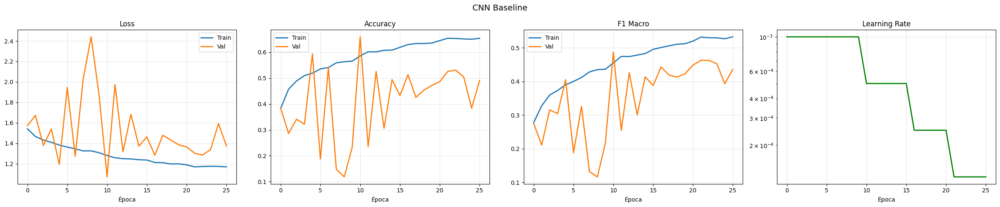

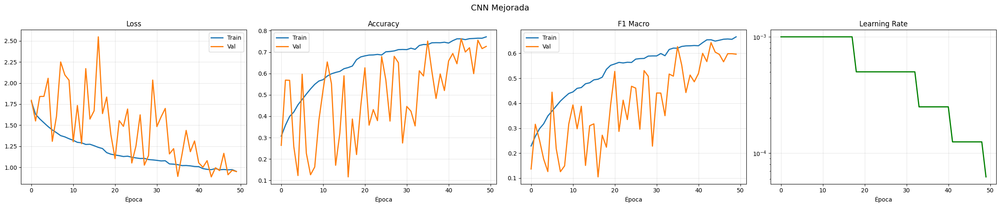

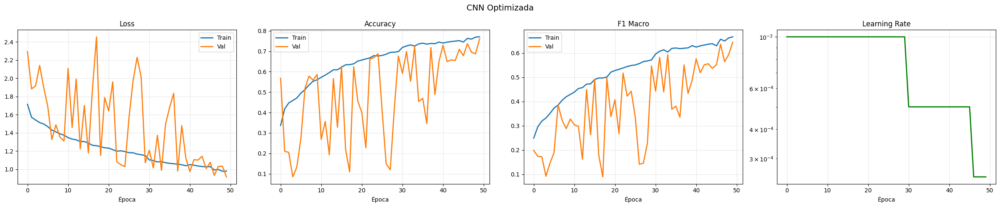

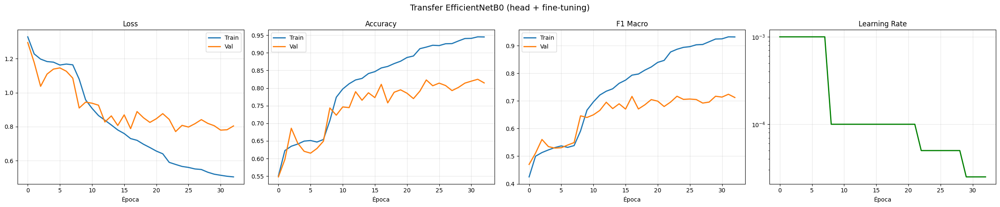

In [ ]:
def plot_training_history(history, title="", save_path=None):
    fig, axes = plt.subplots(1, 4, figsize=(24, 5))

    # Loss
    axes[0].plot(history.history['loss'], label='Train', linewidth=2)
    axes[0].plot(history.history['val_loss'], label='Val', linewidth=2)
    axes[0].set_title('Loss'); axes[0].set_xlabel('Época')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    # Accuracy
    axes[1].plot(history.history['accuracy'], label='Train', linewidth=2)
    axes[1].plot(history.history['val_accuracy'], label='Val', linewidth=2)
    axes[1].set_title('Accuracy'); axes[1].set_xlabel('Época')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    # F1 macro (métrica principal)
    axes[2].plot(history.history['f1_macro'], label='Train', linewidth=2)
    axes[2].plot(history.history['val_f1_macro'], label='Val', linewidth=2)
    axes[2].set_title('F1 Macro'); axes[2].set_xlabel('Época')
    axes[2].legend(); axes[2].grid(True, alpha=0.3)

    # Learning Rate (Keras 3 lo registra como 'learning_rate'; versiones anteriores como 'lr')
    lr_key = 'learning_rate' if 'learning_rate' in history.history else 'lr'
    if lr_key in history.history:
        axes[3].plot(history.history[lr_key], linewidth=2, color='green')
        axes[3].set_title('Learning Rate'); axes[3].set_xlabel('Época')
        axes[3].set_yscale('log'); axes[3].grid(True, alpha=0.3)

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

# Graficar para cada modelo
for name, hist, log_dir in [
    ("CNN Baseline", history_baseline, log_baseline),
    ("CNN Mejorada", history_improved, log_improved),
    ("CNN Optimizada", history_optimized, log_optimized),
    ("Transfer EfficientNetB0 (head + fine-tuning)", history_transfer, log_transfer)
]:
    plot_training_history(hist, title=name, save_path=f"{log_dir}/training_curves.png")

### 📝 Pregunta de Análisis
Observe las curvas de los 4 modelos (en el Modelo 4, el salto a mitad de la curva marca el inicio del fine-tuning). ¿Cuál muestra mejor ajuste? ¿Alguno presenta overfitting o underfitting?

**Respuesta:**
- **CNN Baseline:** **underfitting**. La accuracy de entrenamiento solo llega a ~0.65 y la de validación oscila muchísimo (entre ~0.12 y ~0.66 de una época a otra). Es una red demasiado pequeña para fotos de campo: su mejor val F1 macro fue 0.487 (época 11) y EarlyStopping la detuvo en la época 26.
- **CNN Mejorada y CNN Optimizada:** aprenden de forma sostenida (train accuracy ≈ 0.77 al final), pero la validación es **muy inestable** durante las primeras ~35 épocas (val accuracy entre ~0.10 y ~0.70): la red residual entrenada desde cero, con BatchNorm, todavía no estabiliza sus estadísticas y en algunas épocas predice casi todo como una sola clase. Se estabiliza cuando ReduceLROnPlateau baja el learning rate. No hay overfitting fuerte: train y val terminan cerca (val F1 0.643 y 0.645). Ambas usaron las 50 épocas; la Optimizada logró su mejor valor justo en la última, así que probablemente se beneficiaría de más épocas.
- **Transfer EfficientNetB0:** es el **mejor ajuste en validación** (val F1 0.724, val accuracy 0.825) y aprende mucho más rápido: en la fase 1 (base congelada) ya llega a val F1 0.56, y el fine-tuning lo sube a 0.72. Desde la época ~12 del fine-tuning aparece **overfitting moderado**: la accuracy de entrenamiento sube hasta 0.95, mientras que la de validación se estanca en ~0.80–0.82.

> **Nota sobre los callbacks:** `EarlyStopping` vigila `val_loss` y restauró los pesos de la época 16 del fine-tuning (menor val_loss = 0.771, val F1 = 0.717); `ModelCheckpoint` vigila `val_f1_macro` y guardó la época 24 (val F1 = 0.724). El modelo evaluado en test y desplegado es el de la época 16. Para una próxima versión conviene que ambos callbacks vigilen la misma métrica.

**Decisión de diseño:** como la pérdida de validación era muy inestable y detenía el entrenamiento antes de tiempo, aumentamos la paciencia de EarlyStopping de 10 a 15 épocas.


---
## 📊 Fase 6: Suite de Evaluación Completa

Elegimos el **mejor modelo según el F1 macro de validación** (no de test, para no hacer trampa) y lo evaluamos **una sola vez sobre el conjunto de test**, que el modelo nunca vio.

In [ ]:
# Seleccionar el mejor modelo por F1 macro en VALIDACIÓN
candidates = {
    "CNN Baseline":   (model_baseline,  history_baseline,  log_baseline,  ckpt_baseline),
    "CNN Mejorada":   (model_improved,  history_improved,  log_improved,  ckpt_improved),
    "CNN Optimizada": (model_optimized, history_optimized, log_optimized, ckpt_optimized),
    "Transfer EfficientNetB0": (model_transfer, history_transfer, log_transfer, ckpt_transfer),
}
best_name = max(candidates, key=lambda n: max(candidates[n][1].history['val_f1_macro']))
model, best_history, best_log, best_ckpt = candidates[best_name]
for n, (_, h, _, _) in candidates.items():
    print(f"  {n:<24} mejor val_f1_macro = {max(h.history['val_f1_macro']):.4f}")
print(f"\n🏆 Mejor modelo: {best_name}")

# Obtener predicciones sobre TEST
y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

# Obtener etiquetas reales
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])

print(f"Predicciones: {len(y_pred)}")
print(f"Etiquetas reales: {len(y_true)}")

  CNN Baseline             mejor val_f1_macro = 0.4869
  CNN Mejorada             mejor val_f1_macro = 0.6427
  CNN Optimizada           mejor val_f1_macro = 0.6448
  Transfer EfficientNetB0  mejor val_f1_macro = 0.7242

🏆 Mejor modelo: Transfer EfficientNetB0
101/101 ━━━━━━━━━━━━━━━━━━━━ 14s 84ms/step
Predicciones: 3210
Etiquetas reales: 3210


### 6.1 Classification Report

In [ ]:
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
test_f1_macro = f1_score(y_true, y_pred, average='macro')
test_accuracy = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_accuracy:.4f} | Test F1 macro: {test_f1_macro:.4f}")

              precision    recall  f1-score   support

         CBB     0.5786    0.5644    0.5714       163
        CBSD     0.7281    0.7325    0.7303       329
         CGM     0.6228    0.7933    0.6978       358
         CMD     0.9689    0.8840    0.9245      1974
     Healthy     0.6069    0.7280    0.6620       386

    accuracy                         0.8234      3210
   macro avg     0.7011    0.7404    0.7172      3210
weighted avg     0.8423    0.8234    0.8298      3210

Test Accuracy: 0.8234 | Test F1 macro: 0.7172


### 6.2 Matriz de Confusión Profesional

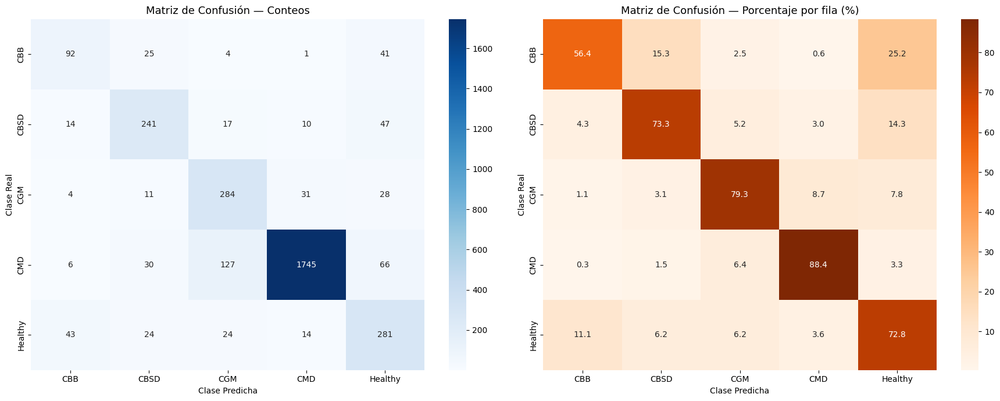

In [ ]:
def plot_confusion_matrix(y_true, y_pred, class_names, save_path=None):
    cm_ = confusion_matrix(y_true, y_pred)
    cm_pct = cm_.astype('float') / cm_.sum(axis=1)[:, np.newaxis] * 100

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    sns.heatmap(cm_, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title('Matriz de Confusión — Conteos', fontsize=13)
    axes[0].set_ylabel('Clase Real'); axes[0].set_xlabel('Clase Predicha')

    sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Oranges',
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title('Matriz de Confusión — Porcentaje por fila (%)', fontsize=13)
    axes[1].set_ylabel('Clase Real'); axes[1].set_xlabel('Clase Predicha')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

plot_confusion_matrix(y_true, y_pred, class_names, f"{best_log}/confusion_matrix.png")

### 6.3 Curvas ROC Multiclase

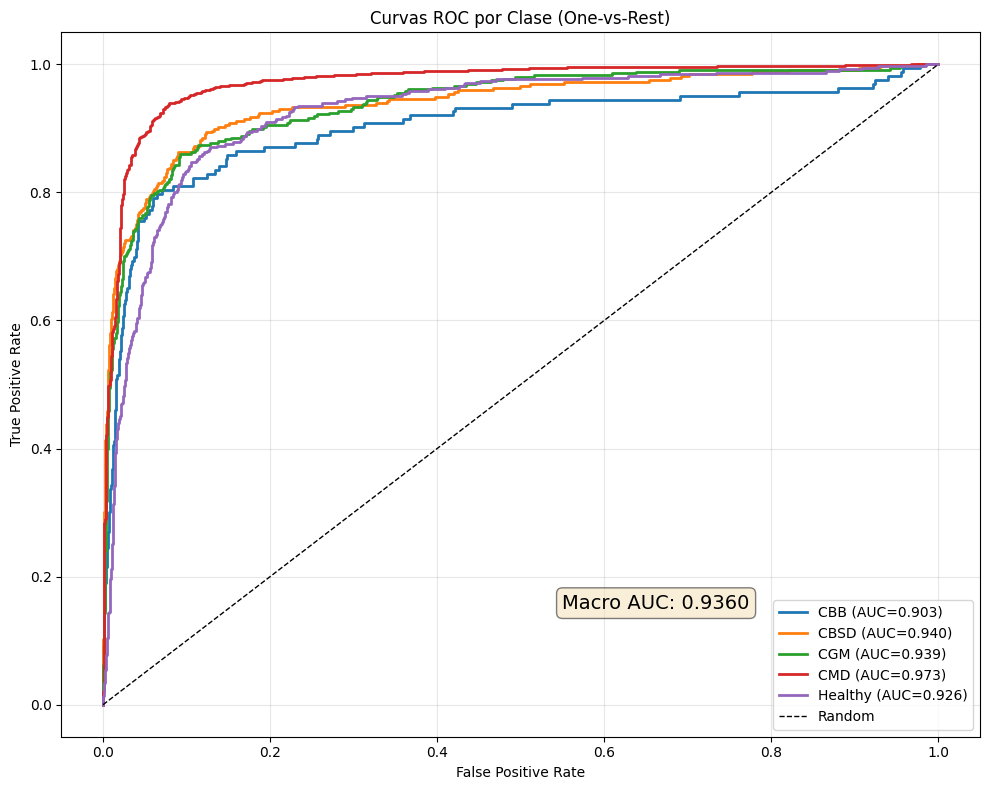

Macro AUC: 0.9360


In [ ]:
def plot_roc_curves(y_true, y_pred_probs, class_names, save_path=None):
    n_classes = len(class_names)
    y_true_bin = label_binarize(y_true, classes=range(n_classes))

    fig, ax = plt.subplots(figsize=(10, 8))

    # Con 5 clases podemos graficarlas todas
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, linewidth=2, label=f'{class_names[i]} (AUC={roc_auc:.3f})')

    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title('Curvas ROC por Clase (One-vs-Rest)')
    ax.legend(loc='lower right', fontsize=10)
    ax.grid(True, alpha=0.3)

    # Macro AUC
    macro_auc = roc_auc_score(y_true_bin, y_pred_probs, multi_class='ovr', average='macro')
    ax.text(0.55, 0.15, f'Macro AUC: {macro_auc:.4f}', fontsize=14,
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    return macro_auc

macro_auc = plot_roc_curves(y_true, y_pred_probs, class_names, f"{best_log}/roc_curves.png")
print(f"Macro AUC: {macro_auc:.4f}")

### 📝 Interpretación de la evaluación
Resultados del mejor modelo (**Transfer EfficientNetB0**, 256×256) sobre las **3,210 imágenes de test**, que el modelo nunca vio:

| Métrica | Valor | Versión anterior (192 px) |
|---|---|---|
| Accuracy | **82.3%** | 79.5% |
| F1 macro | **0.717** | 0.689 |
| F1 ponderado | 0.830 | 0.805 |
| Macro AUC | **0.936** | 0.943 |

- **Mejor clase: CMD** (F1 0.925, precisión 0.969). Es la clase con más ejemplos y la de síntomas más característicos (mosaico y deformación de la hoja).
- **Clases intermedias:** CBSD (F1 0.730), CGM (0.698) y Healthy (0.662). CBSD fue la que más mejoró con la mayor resolución (0.664 → 0.730): sus rayas finas en las venas se ven mejor a 256 px.
- **Clase más difícil: CBB** (F1 0.571, precisión 0.579, recall 0.564). Tiene muy pocas imágenes (761 en train).
- En CBSD, CGM y Healthy el **recall es mayor que la precisión**: es el efecto esperado del `class_weight` (preferimos no dejar pasar una hoja enferma, aunque haya algunas falsas alarmas). En CBB ambos valores quedaron parejos.

**Comparación con los baselines de la Fase 1:** el modelo supera claramente al clasificador aleatorio (20% de accuracy) y al de "siempre CMD" (61.5% de accuracy, F1 macro ≈ 0.15). El F1 macro de 0.717 muestra que reconoce **las 5 clases**, no solo la mayoritaria.

**Macro AUC = 0.936:** si se elige al azar una foto de una clase y otra de otra clase, en el 94% de los casos el modelo le da más probabilidad a la clase correcta. Bajó levemente respecto a la versión de 192 px (0.943) aunque la accuracy y el F1 subieron: el modelo acierta más veces, pero sus probabilidades están algo peor calibradas (ver errores con alta confianza en la Fase 7).


---
## 🔬 Fase 7: Análisis de Errores

In [ ]:
def analyze_top_errors(y_true, y_pred, class_names, top_k=10):
    cm_ = confusion_matrix(y_true, y_pred)
    np.fill_diagonal(cm_, 0)

    errors = []
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            if cm_[i, j] > 0:
                errors.append({
                    'real': class_names[i],
                    'predicha': class_names[j],
                    'count': cm_[i, j]
                })

    errors.sort(key=lambda x: x['count'], reverse=True)

    print(f"{'Real':<15} {'Predicha':<15} {'Errores':>8}")
    print("=" * 40)
    for err in errors[:top_k]:
        print(f"{err['real']:<15} {err['predicha']:<15} {err['count']:>8}")

    return errors[:top_k]

top_errors = analyze_top_errors(y_true, y_pred, class_names)

Real            Predicha         Errores
CMD             CGM                  127
CMD             Healthy               66
CBSD            Healthy               47
Healthy         CBB                   43
CBB             Healthy               41
CGM             CMD                   31
CMD             CBSD                  30
CGM             Healthy               28
CBB             CBSD                  25
Healthy         CBSD                  24


### 7.1 Errores con Alta Confianza
Los errores más preocupantes son aquellos en los que el modelo se equivoca **muy seguro**: pueden indicar overfitting, etiquetas incorrectas en el dataset o clases visualmente muy parecidas.

Total de errores en test: 567 de 3210 (17.7%)
Errores con confianza > 90%: 61


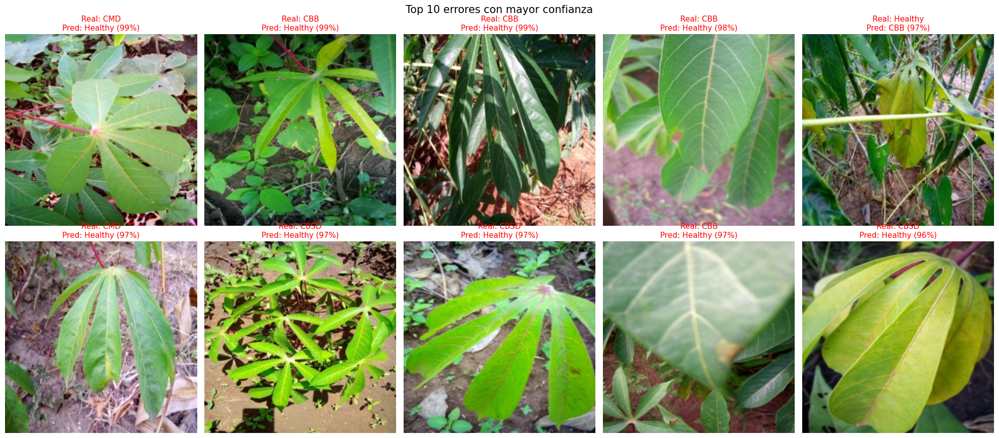

In [ ]:
# Errores ordenados por la confianza con la que el modelo se equivocó
wrong_idx = np.where(y_pred != y_true)[0]
wrong_conf = y_pred_probs[wrong_idx, y_pred[wrong_idx]]
top_wrong = wrong_idx[np.argsort(wrong_conf)[::-1][:10]]

print(f"Total de errores en test: {len(wrong_idx)} de {len(y_true)} ({len(wrong_idx)/len(y_true):.1%})")
print(f"Errores con confianza > 90%: {(wrong_conf > 0.9).sum()}")

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
for ax, idx in zip(axes.flat, top_wrong):
    ax.imshow(Image.open(test_file_paths[idx]))
    ax.set_title(f"Real: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]} "
                 f"({y_pred_probs[idx, y_pred[idx]]:.0%})", fontsize=11, color='red')
    ax.axis('off')
plt.suptitle('Top 10 errores con mayor confianza', fontsize=15)
plt.tight_layout()
plt.savefig(f"{best_log}/high_confidence_errors.png", dpi=150, bbox_inches='tight')
plt.show()

### 7.2 Explicabilidad con Grad-CAM (Sesión 07)
Grad-CAM es el "examen con resaltador": muestra **qué zona de la imagen** usó el modelo para decidir. Lo aplicamos a aciertos y a errores para verificar si el modelo mira la hoja enferma (✅) o el fondo / la mano / el suelo (❌ atajo o *shortcut*).

Capa usada para Grad-CAM: efficientnetb0


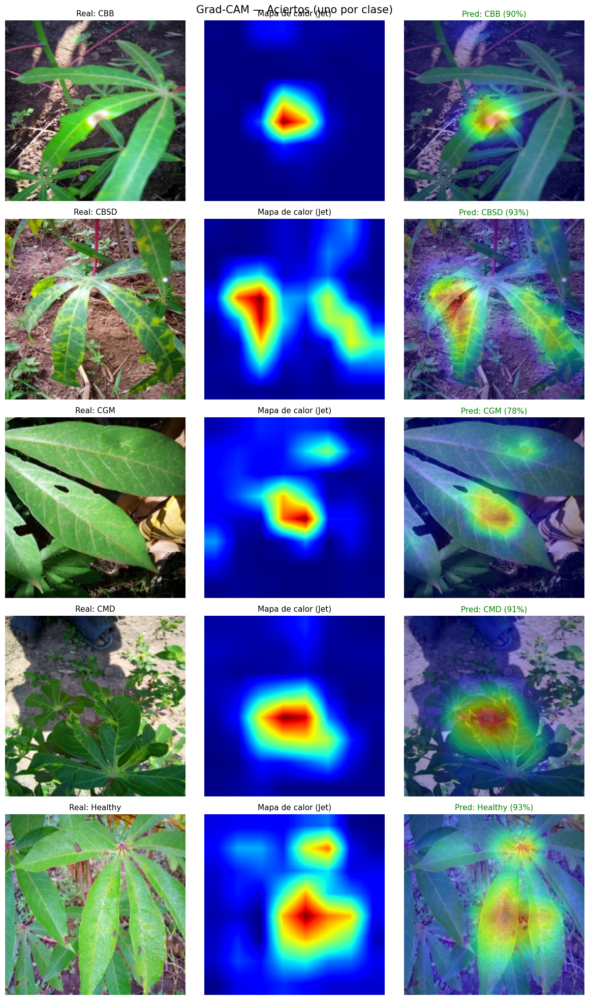

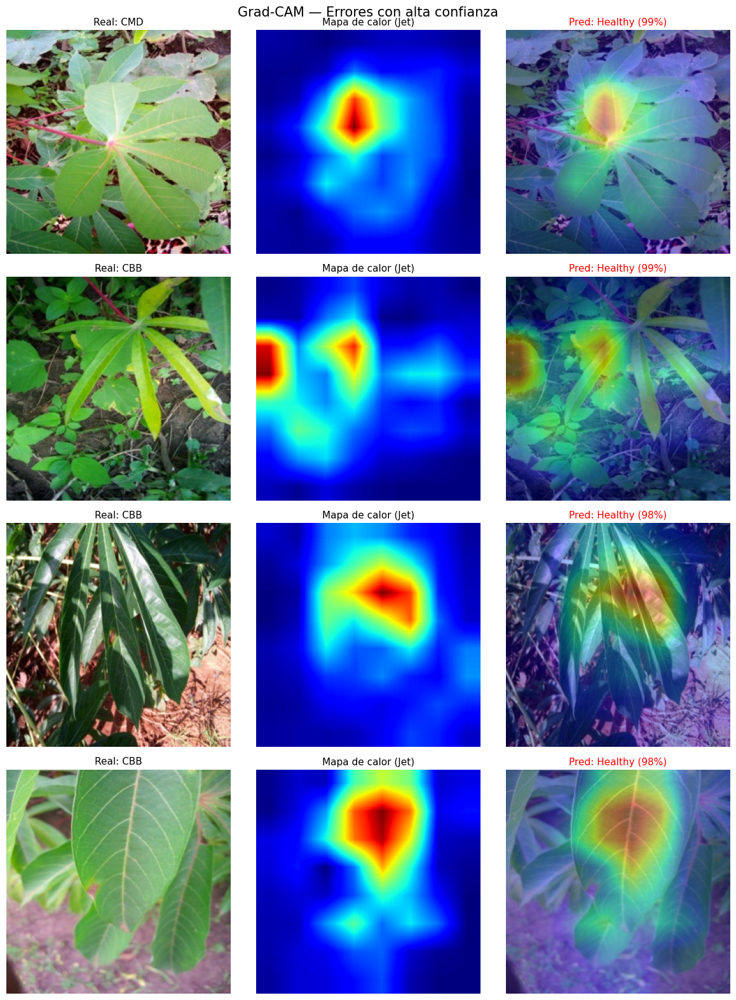

In [ ]:
from PIL import ImageOps   # respeta la orientación de fotos tomadas con celular

def get_last_conv_layer_name(model):
    # Última capa con salida 4D (mapas de características) antes del GlobalAveragePooling
    for layer in reversed(model.layers):
        try:
            if len(layer.output.shape) == 4:
                return layer.name
        except Exception:
            continue
    raise ValueError("No se encontró una capa convolucional")

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    capa_objetivo = model.get_layer(last_conv_layer_name)
    with tf.GradientTape() as tape:
        if isinstance(capa_objetivo, tf.keras.Model):
            # Modelo preentrenado anidado (transfer learning): recorrer las capas en orden
            x = tf.convert_to_tensor(img_array)
            conv_output = None
            for layer in model.layers:
                if isinstance(layer, tf.keras.layers.InputLayer):
                    continue
                x = layer(x)
                if layer is capa_objetivo:
                    conv_output = x
                    tape.watch(conv_output)
            predicciones = x
        else:
            grad_model = tf.keras.Model(model.inputs, [capa_objetivo.output, model.output])
            conv_output, predicciones = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predicciones[0])
        clase_output = predicciones[:, pred_index]

    gradientes = tape.gradient(clase_output, conv_output)        # [2] Calcular
    pesos = tf.reduce_mean(gradientes, axis=(0, 1, 2))            # [3] Promediar
    heatmap = tf.reduce_sum(conv_output[0] * pesos, axis=-1)      # [4] Combinar
    heatmap = tf.nn.relu(heatmap)                                 # [5] Filtrar (solo lo que suma)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def show_gradcam(file_path, model, last_conv_layer_name, true_label=None, ax_row=None, alpha=0.4):
    img = ImageOps.exif_transpose(Image.open(file_path)).convert('RGB').resize(IMG_SIZE, Image.BILINEAR)
    img_arr = np.array(img).astype('float32') / 255.0
    probs = model.predict(img_arr[np.newaxis], verbose=0)[0]
    pred = int(np.argmax(probs))

    heatmap = make_gradcam_heatmap(img_arr[np.newaxis], model, last_conv_layer_name, pred)
    heatmap_resized = np.array(Image.fromarray(np.uint8(255 * heatmap)).resize(IMG_SIZE, Image.BILINEAR)) / 255.0   # [6] Escalar
    heatmap_colored = cm.jet(heatmap_resized)[:, :, :3]
    superimposed = np.clip(heatmap_colored * alpha + img_arr * (1 - alpha), 0, 1)

    titulo_real = f"Real: {class_names[true_label]}" if true_label is not None else "Imagen original"
    color = 'green' if true_label is None or true_label == pred else 'red'
    ax_row[0].imshow(img_arr); ax_row[0].set_title(titulo_real, fontsize=11)
    ax_row[1].imshow(heatmap_resized, cmap='jet'); ax_row[1].set_title('Mapa de calor (Jet)', fontsize=11)
    ax_row[2].imshow(superimposed)
    ax_row[2].set_title(f"Pred: {class_names[pred]} ({probs[pred]:.0%})", fontsize=11, color=color)
    for a in ax_row:
        a.axis('off')

last_conv = get_last_conv_layer_name(model)
print(f"Capa usada para Grad-CAM: {last_conv}")

# Un acierto por clase
correct_idx = np.where(y_pred == y_true)[0]
ejemplos_ok = [correct_idx[y_true[correct_idx] == c][0] for c in range(NUM_CLASSES)
               if (y_true[correct_idx] == c).any()]
fig, axes = plt.subplots(len(ejemplos_ok), 3, figsize=(12, 4 * len(ejemplos_ok)))
for row, idx in zip(axes, ejemplos_ok):
    show_gradcam(test_file_paths[idx], model, last_conv, y_true[idx], row)
plt.suptitle('Grad-CAM — Aciertos (uno por clase)', fontsize=15)
plt.tight_layout()
plt.savefig(f"{best_log}/gradcam_aciertos.png", dpi=150, bbox_inches='tight')
plt.show()

# Errores con alta confianza
fig, axes = plt.subplots(4, 3, figsize=(12, 16))
for row, idx in zip(axes, top_wrong[:4]):
    show_gradcam(test_file_paths[idx], model, last_conv, y_true[idx], row)
plt.suptitle('Grad-CAM — Errores con alta confianza', fontsize=15)
plt.tight_layout()
plt.savefig(f"{best_log}/gradcam_errores.png", dpi=150, bbox_inches='tight')
plt.show()

### 📝 Diagnóstico Grad-CAM
**Aciertos (uno por clase):** el calor se concentra en **la hoja y en sus lesiones**, no en el fondo. En **CBB** (90%) se enfoca en la mancha necrótica blanca; en **CBSD** (93%), en la hoja con manchas y rayas amarillas; en **CGM** (78%), en la zona de la hoja con moteado; en **CMD** (91%), en la planta del centro, mientras que los pies y la sombra de la parte superior casi no reciben peso; en **Healthy** (93%), en las hojas centrales. ✅ **El modelo mira el lugar correcto.**

**Errores con alta confianza:** 9 de los 10 errores más seguros son hojas enfermas que el modelo llamó **Healthy** con 96–99% de confianza:
- **CMD → Healthy (99%) y CBB → Healthy (98%, dos casos):** el calor está sobre la hoja, pero en esas fotos **casi no se ven síntomas** (hoja uniformemente verde, hojas en sombra o foto desenfocada de muy cerca). Son síntomas leves, fotos de baja calidad o posibles **etiquetas incorrectas** del dataset.
- **CBB → Healthy (99%):** parte del calor cae sobre **maleza del fondo** (lado izquierdo) y no sobre la yuca. Es el único caso en que el modelo se apoya en el entorno, una señal leve de **atajo (shortcut)** que conviene vigilar.

**Conclusión:** el modelo aprendió a mirar la hoja. Sus errores vienen sobre todo de **hojas con síntomas poco visibles**, de **fotos de baja calidad** y de **posibles etiquetas ruidosas**. Los errores con más de 90% de confianza subieron de 11 (192 px) a **61**: el modelo se equivoca menos, pero cuando falla lo hace con más seguridad, por lo que conviene **calibrar sus probabilidades**.


### 📝 Tabla de Mejoras (Diagnostic Matrix)
Basada en el top de confusiones (567 errores de 3,210, es decir 17.7%; antes 657 a 192 px), los errores con alta confianza y Grad-CAM:

| Síntoma (Hallazgo) | Causa probable | Tratamiento (Acción correctiva) |
|---|---|---|
| **CMD → CGM (127):** la principal fuente de error. CMD → CBSD bajó de 68 a 30 al subir la resolución | Enfermedades virales con clorosis y moteado parecidos; además, el dataset tiene etiquetas ruidosas | Subir la resolución a 384 px (a 256 ya mejoró CMD → CBSD); más ejemplos de CGM; test-time augmentation |
| **Enfermas → Healthy:** CMD (66), CBSD (47) y CGM (28) | Síntomas leves o tempranos, o fotos de planta completa donde la hoja enferma ocupa poco espacio | Recortes centrados en las hojas; augmentation de zoom más agresivo; guiar al usuario para fotografiar la hoja de cerca |
| **Healthy → CBB (43) y CBB → Healthy (41):** CBB tiene la peor precisión (0.58) | Muy pocas imágenes de CBB (761 en train); su `class_weight` alto (3.94) empuja falsas alarmas; quemaduras de sol o daño mecánico se parecen a lesiones | Conseguir más fotos de CBB; ajustar umbrales de decisión por clase con el conjunto de validación |
| **61 errores con confianza > 90%**, casi todos predichos como Healthy (Grad-CAM: síntomas poco visibles, fotos desenfocadas o en sombra, un caso apoyado en el fondo) | Imágenes ambiguas, posibles etiquetas incorrectas y probabilidades sobreconfiadas | Revisar esas etiquetas; calibrar las probabilidades (temperature scaling); mantener el umbral de "Incierto" (< 50%) que ya usa la app web |


---
## 📈 Fase 8: Comparación Sistemática de Modelos
Comparamos los 4 modelos con las mismas métricas: las de validación (durante el entrenamiento) y las de **test** (Accuracy, F1 macro, AUC), frente a su complejidad (parámetros y tamaño).

In [ ]:
results = []
test_metrics = {}
for name, (m, history, _, _) in candidates.items():
    best_val_acc = max(history.history['val_accuracy'])
    best_val_f1 = max(history.history['val_f1_macro'])
    best_val_loss = min(history.history['val_loss'])
    total_epochs = len(history.history['loss'])
    params = m.count_params()

    probs = m.predict(test_ds, verbose=0)
    preds = np.argmax(probs, axis=1)
    t_acc = accuracy_score(y_true, preds)
    t_f1 = f1_score(y_true, preds, average='macro')
    t_auc = roc_auc_score(label_binarize(y_true, classes=range(NUM_CLASSES)), probs,
                          multi_class='ovr', average='macro')
    test_metrics[name] = {'accuracy': t_acc, 'f1_macro': t_f1, 'auc': t_auc}

    results.append({
        'Modelo': name,
        'Val Accuracy': f"{best_val_acc:.4f}",
        'Val F1 macro': f"{best_val_f1:.4f}",
        'Val Loss': f"{best_val_loss:.4f}",
        'Test Accuracy': f"{t_acc:.4f}",
        'Test F1 macro': f"{t_f1:.4f}",
        'Test AUC': f"{t_auc:.4f}",
        'Parámetros': f"{params:,}",
        'Épocas': total_epochs,
        'Tamaño (MB)': f"{params*4/1024/1024:.1f}",
    })

df_results = pd.DataFrame(results)
df_results.to_csv(f"{best_log}/model_comparison.csv", index=False)
print(df_results.to_string(index=False))

                 Modelo Val Accuracy Val F1 macro Val Loss Test Accuracy Test F1 macro Test AUC Parámetros  Épocas Tamaño (MB)
           CNN Baseline       0.6592       0.4869   1.0728        0.6583        0.4755   0.8585    128,453      26         0.5
           CNN Mejorada       0.7623       0.6427   0.8867        0.7698        0.6415   0.9323  2,925,701      50        11.2
         CNN Optimizada       0.7601       0.6448   0.9158        0.7626        0.6437   0.9283  3,055,749      50        11.7
Transfer EfficientNetB0       0.8249       0.7242   0.7713        0.8234        0.7172   0.9360  4,055,976      33        15.5


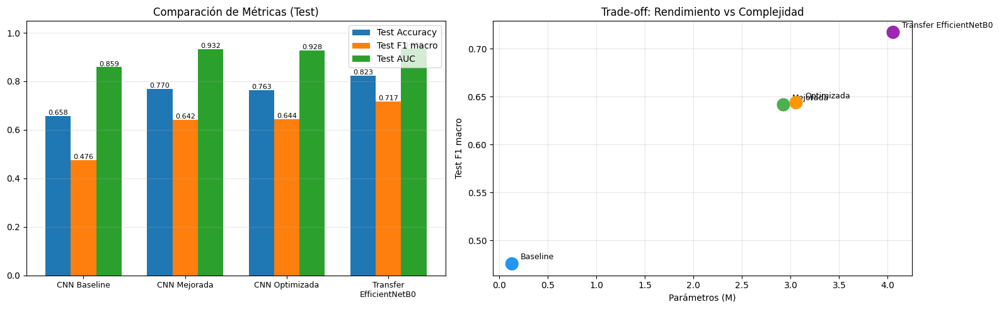

In [ ]:
# Gráfico de barras comparativo + trade-off
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
model_names = list(test_metrics.keys())
metric_keys = [('accuracy', 'Test Accuracy'), ('f1_macro', 'Test F1 macro'), ('auc', 'Test AUC')]
x = np.arange(len(model_names))
w = 0.25
colores = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0', '#795548'][:len(model_names)]
for k, (key, label) in enumerate(metric_keys):
    vals = [test_metrics[n][key] for n in model_names]
    bars = axes[0].bar(x + (k - 1) * w, vals, w, label=label)
    for b, v in zip(bars, vals):
        axes[0].text(b.get_x() + b.get_width()/2, v + 0.005, f'{v:.3f}', ha='center', fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels([n.replace('Transfer ', 'Transfer\n') for n in model_names], fontsize=9)
axes[0].set_title('Comparación de Métricas (Test)')
axes[0].set_ylim([0, 1.05]); axes[0].legend(); axes[0].grid(True, alpha=0.3, axis='y')

# Trade-off scatter
f1s = [test_metrics[n]['f1_macro'] for n in model_names]
params_m = [int(r['Parámetros'].replace(',', '')) / 1e6 for r in results]
axes[1].scatter(params_m, f1s, s=200, c=colores, zorder=5)
for i, name in enumerate(model_names):
    axes[1].annotate(name.replace('CNN ', ''), (params_m[i], f1s[i]),
                     textcoords="offset points", xytext=(10, 5), fontsize=9)
axes[1].set_xlabel('Parámetros (M)')
axes[1].set_ylabel('Test F1 macro')
axes[1].set_title('Trade-off: Rendimiento vs Complejidad')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{best_log}/model_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

### 📝 Pregunta de Producción
¿Cuál modelo seleccionaría para producción si el requisito es **< 10 MB para móviles** (celulares de los agricultores)?

**Respuesta: Transfer EfficientNetB0, exportado a TFLite Float16.**

| Modelo | Test F1 macro | Test Accuracy | Parámetros | Tamaño Keras (float32) |
|---|---|---|---|---|
| CNN Baseline | 0.476 | 65.8% | 128 K | 0.5 MB |
| CNN Mejorada | 0.642 | 77.0% | 2.93 M | 11.2 MB |
| CNN Optimizada | 0.644 | 76.3% | 3.06 M | 11.7 MB |
| **Transfer EfficientNetB0** | **0.717** | **82.3%** | 4.06 M | 15.5 MB |

- Es el mejor en todas las métricas de clasificación: **+0.07 de F1 macro y unos 5–6 puntos de accuracy** frente a las CNN residuales, con solo 1 millón de parámetros más.
- En float32 pesa 15.5 MB y **no cumple** el límite, pero al cuantizarlo a **TFLite Float16 pesa 7.8 MB ✅**. Además **conserva el comportamiento**: coincide en un 99.0% con el modelo original (Fase 12.1).
- El Baseline es el más liviano (0.5 MB), pero con F1 macro 0.48 no sirve para diagnosticar. Las CNN Mejorada y Optimizada quedaron prácticamente empatadas (F1 0.642 vs 0.644); la regularización extra de la Optimizada no marcó diferencia a 256 px.
- **Trade-off:** en la gráfica, el transfer learning logra el mejor rendimiento sin un aumento grande de complejidad, porque reutiliza lo aprendido en ImageNet en lugar de aprenderlo todo desde cero.


---
## 💾 Fases 9-11: Versionado, Logging y Documentación

### Fase 9: Versionado del Proyecto (MLOps Básico)
Estructura de carpetas, `.gitignore` y **metadata del modelo** (el "DNI" del experimento). Regla de oro: **Git es para código, no para pesos ni datos.**

In [ ]:
# .gitignore: no versionar datos crudos/procesados ni modelos pesados
gitignore = '''# Datos (usar DVC o Drive, no Git)
data/raw/
data/processed/
# Pesos de modelos
*.keras
*.h5
*.tflite
# Logs pesados de TensorBoard
experiments/logs/**/events.out.tfevents.*
# Credenciales
kaggle.json
'''
with open('.gitignore', 'w') as f:
    f.write(gitignore)

def save_model_metadata(model, history, config, dataset_info, save_path, test_results=None):
    metadata = {
        'version': '1.0',
        'timestamp': datetime.datetime.now().isoformat(),
        'model': {
            'architecture': model.name,
            'total_params': model.count_params(),
            'input_shape': list(model.input_shape[1:]),
            'output_classes': model.output_shape[-1],
            'class_names': class_names,
        },
        'training': {
            'config': config,
            'best_val_accuracy': float(max(history.history['val_accuracy'])),
            'best_val_f1_macro': float(max(history.history['val_f1_macro'])),
            'best_val_loss': float(min(history.history['val_loss'])),
            'final_epoch': len(history.history['loss']),
        },
        'test_results': test_results or {},
        'dataset': dataset_info,
        'environment': {
            'tensorflow': tf.__version__,
            'python': platform.python_version(),
            'gpu': str(tf.config.list_physical_devices('GPU')),
        }
    }
    with open(save_path, 'w') as f:
        json.dump(metadata, f, indent=2, default=str)
    print(f"✅ Metadata guardada: {save_path}")
    return metadata

# Guardar metadata del mejor modelo
dataset_info = {
    'name': 'Cassava Leaf Disease Classification (Kaggle 2020)',
    'classes': NUM_CLASSES,
    'class_counts': class_counts,
    'total_images': int(len(df)),
    'split': {'train': len(train_df), 'val': len(val_df), 'test': len(test_df)},
    'img_size': list(IMG_SIZE),
}
metadata = save_model_metadata(
    model, best_history, CONFIG, dataset_info,
    f"{best_ckpt}/metadata.json",
    test_results={k: float(v) for k, v in test_metrics[best_name].items()}
)
print(json.dumps(metadata, indent=2, default=str))

# Mostrar estructura del proyecto (sin listar las miles de imágenes)
print("\n📁 Estructura del proyecto:")
for root, dirs, files in os.walk('.'):
    depth = root.count(os.sep)
    if 'data' in root.split(os.sep) and depth > 2:
        continue
    if depth > 3:
        continue
    print('  ' * depth + f"📂 {os.path.basename(root) or 'proyecto_cassava'}/")
    if 'data' not in root:
        for fname in files[:6]:
            print('  ' * (depth + 1) + f"📄 {fname}")

✅ Metadata guardada: experiments/checkpoints/transfer_ft_20261108_214948/metadata.json
{
  "version": "1.0",
  "timestamp": "2026-11-08T23:59:06.432968",
  "model": {
    "architecture": "transfer_efficientnetb0",
    "total_params": 4055976,
    "input_shape": [
      256,
      256,
      3
    ],
    "output_classes": 5,
    "class_names": [
      "CBB",
      "CBSD",
      "CGM",
      "CMD",
      "Healthy"
    ]
  },
  "training": {
    "config": {
      "learning_rate": 0.001,
      "epochs": 50,
      "batch_size": 32,
      "img_size": [
        256,
        256
      ],
      "optimizer": "adam",
      "weight_decay": 0.0001,
      "label_smoothing": 0.1,
      "use_class_weight": true,
      "seed": 42
    },
    "best_val_accuracy": 0.8249221444129944,
    "best_val_f1_macro": 0.724155068397522,
    "best_val_loss": 0.7713021636009216,
    "final_epoch": 33
  },
  "test_results": {
    "accuracy": 0.8233644859813084,
    "f1_macro": 0.7171957704478238,
    "auc": 0.93603216

### Fase 10: Logging y Registro de Experimentos
Cada entrenamiento dejó tres registros persistentes: `experiment.log` (callback personalizado), `training_log.csv` (CSVLogger) y los eventos de TensorBoard. **No dependemos del output efímero de la consola.**

In [ ]:
# Revisar el experiment.log del mejor modelo
print(f"📄 {best_log}/experiment.log\n")
with open(f"{best_log}/experiment.log", encoding='utf-8') as f:
    lines = f.readlines()
print(''.join(lines[:5]) + '   ...\n' + ''.join(lines[-3:]))

# Revisar el CSV del entrenamiento
pd.read_csv(f"{best_log}/training_log.csv").tail()

📄 experiments/logs/transfer_ft_20261108_214948/experiment.log

[2026-11-08 23:34:35] INFO: Inicio del experimento transfer_ft_20261108_214948 | params=4,055,976
[2026-11-08 23:37:03] INFO: Época 1: loss=1.0791, acc=0.7077, val_loss=0.9098, val_acc=0.7436, val_f1_macro=0.6461
[2026-11-08 23:37:55] INFO: Época 2: loss=0.9579, acc=0.7740, val_loss=0.9444, val_acc=0.7231, val_f1_macro=0.6402
[2026-11-08 23:38:47] INFO: Época 3: loss=0.9078, acc=0.7973, val_loss=0.9380, val_acc=0.7464, val_f1_macro=0.6497
[2026-11-08 23:39:39] INFO: Época 4: loss=0.8656, acc=0.8122, val_loss=0.9263, val_acc=0.7445, val_f1_macro=0.6657
   ...
[2026-11-08 23:56:50] INFO: Época 24: loss=0.5088, acc=0.9454, val_loss=0.7821, val_acc=0.8249, val_f1_macro=0.7242
[2026-11-08 23:57:41] INFO: Época 25: loss=0.5052, acc=0.9450, val_loss=0.8044, val_acc=0.8146, val_f1_macro=0.7124
[2026-11-08 23:57:42] INFO: Fin del entrenamiento | duración=23.1 min



,epoch,accuracy,auc,f1_macro,learning_rate,loss,val_accuracy,val_auc,val_f1_macro,val_loss
20,20,0.933698,0.993593,0.914260,0.000050,0.532587,0.801869,0.951096,0.695770,0.819592
21,21,0.940576,0.994873,0.924112,0.000025,0.520981,0.814019,0.953833,0.716990,0.805800
22,22,0.941043,0.995048,0.924792,0.000025,0.514654,0.819626,0.960451,0.713916,0.779845
23,23,0.945383,0.995215,0.932066,0.000025,0.508801,0.824922,0.958240,0.724155,0.782119
24,24,0.945049,0.995457,0.931667,0.000025,0.505176,0.814642,0.954342,0.712357,0.804354


In [ ]:
# Telemetría interactiva con TensorBoard (comparar los experimentos de los 4 modelos)
%load_ext tensorboard
%tensorboard --logdir experiments/logs

<IPython.core.display.Javascript object>

### Fase 11: Documentación Técnica
Generamos `README.md` con las 7 secciones (resumen, problema, dataset, metodología, resultados, conclusiones, reproducibilidad) y `requirements.txt`. Los resultados se llenan automáticamente; las conclusiones se completan en el reporte técnico del final.

In [ ]:
# requirements.txt con las versiones exactas usadas
import sklearn, matplotlib, PIL
requirements = f'''tensorflow=={tf.__version__}
numpy=={np.__version__}
pandas=={pd.__version__}
scikit-learn=={sklearn.__version__}
matplotlib=={matplotlib.__version__}
seaborn=={sns.__version__}
Pillow=={PIL.__version__}
flask
requests
kaggle
'''
with open('requirements.txt', 'w') as f:
    f.write(requirements)
print(requirements)

tensorflow==2.21.0
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
Pillow==11.3.0
flask
requests
kaggle



In [ ]:
best_test = test_metrics[best_name]
cols = ['Modelo', 'Test Accuracy', 'Test F1 macro', 'Test AUC', 'Parámetros', 'Tamaño (MB)']
tabla_resultados = '| ' + ' | '.join(cols) + ' |\n|' + '---|' * len(cols) + '\n'
tabla_resultados += '\n'.join('| ' + ' | '.join(str(r[c]) for c in cols) + ' |' for r in results)

readme = f'''# 🌿 Diagnóstico de Enfermedades de la Yuca con CNN

**Curso:** IS056B — Ingeniería del Conocimiento | UNCP 2026-II

## 1. Resumen Ejecutivo
Modelo CNN que clasifica fotos de hojas de yuca en 5 clases (4 enfermedades + sana).
Mejor modelo: **{best_name}** — Test F1 macro **{best_test["f1_macro"]:.4f}**,
Accuracy **{best_test["accuracy"]:.4f}**, Macro AUC **{best_test["auc"]:.4f}**.
Desplegado como API REST (Flask, endpoint `/predict`), exportado a TFLite para móviles y publicado como página web
(Hugging Face Spaces, inferencia en el navegador).

## 2. Definición del Problema
El diagnóstico visual de enfermedades de la yuca depende de técnicos agrícolas escasos y costosos.
Clasificación multiclase (CBB, CBSD, CGM, CMD, Healthy). Métrica principal: F1 macro (dataset desbalanceado).
Restricción: modelo ligero (< 10 MB) para celulares con poca conectividad.

## 3. Dataset (EDA)
Cassava Leaf Disease Classification (Kaggle 2020), {len(df)} imágenes válidas tomadas en campo (Uganda).
Distribución: {class_counts}. Ratio de desbalance {max(class_counts.values())/min(class_counts.values()):.1f}:1.
División estratificada 70/15/15 → train {len(train_df)}, val {len(val_df)}, test {len(test_df)}.

## 4. Metodología y Arquitectura
- Imágenes redimensionadas a {IMG_SIZE[0]}x{IMG_SIZE[1]}, normalizadas a [0,1].
- Data augmentation (solo train): flips, rotación, zoom, brillo y contraste.
- 4 arquitecturas: CNN Baseline, CNN con bloques residuales, CNN optimizada (augmentation interno, L2, doble dropout)
  y Transfer Learning con EfficientNetB0 preentrenada en ImageNet (cabeza + fine-tuning).
- Adam (lr={CONFIG["learning_rate"]}, weight_decay={CONFIG["weight_decay"]}), label smoothing {CONFIG["label_smoothing"]},
  class_weight balanceado, 5 callbacks profesionales + logger personalizado.

## 5. Resultados (Métricas en Test)
{tabla_resultados}

## 6. Conclusiones
Ver reporte técnico en el notebook.

## 7. Reproducibilidad
```bash
pip install -r requirements.txt
# 1) Ejecutar el notebook completo (Restart & Run All) con GPU T4 en Colab
# 2) Levantar la API:
python app.py
# 3) Probar:
curl -X POST -F "file=@hoja.jpg" http://localhost:5000/predict
```
Semilla fija: SEED={SEED}. Configuración completa en `experiments/logs/<experimento>/config.json`
y metadata del modelo en `models/production/metadata.json`.
'''
with open('README.md', 'w', encoding='utf-8') as f:
    f.write(readme)
print(readme)

# 🌿 Diagnóstico de Enfermedades de la Yuca con CNN

**Curso:** IS056B — Ingeniería del Conocimiento | UNCP 2026-II

## 1. Resumen Ejecutivo
Modelo CNN que clasifica fotos de hojas de yuca en 5 clases (4 enfermedades + sana).
Mejor modelo: **Transfer EfficientNetB0** — Test F1 macro **0.7172**,
Accuracy **0.8234**, Macro AUC **0.9360**.
Desplegado como API REST (Flask, endpoint `/predict`), exportado a TFLite para móviles y publicado como página web
(Hugging Face Spaces, inferencia en el navegador).

## 2. Definición del Problema
El diagnóstico visual de enfermedades de la yuca depende de técnicos agrícolas escasos y costosos.
Clasificación multiclase (CBB, CBSD, CGM, CMD, Healthy). Métrica principal: F1 macro (dataset desbalanceado).
Restricción: modelo ligero (< 10 MB) para celulares con poca conectividad.

## 3. Dataset (EDA)
Cassava Leaf Disease Classification (Kaggle 2020), 21397 imágenes válidas tomadas en campo (Uganda).
Distribución: {'CBB': 1087, 'CBSD': 2189, 'CGM': 2386, 'CMD

---
## 🚀 Fase 12: Despliegue

El modelo sale del laboratorio y se vuelve un servicio consumible por dos caminos:
- **Móvil:** exportación a **TFLite** con cuantización **Float16**.
- **Web / Cloud:** **API REST con Flask** (endpoint `POST /predict`).

In [ ]:
# Guardar modelo final (el mejor) + archivos que necesita la API
os.makedirs('models/production', exist_ok=True)
model.save('models/production/model_v1.keras')
shutil.copy(f"{best_ckpt}/metadata.json", 'models/production/metadata.json')
with open('models/production/class_names.json', 'w') as f:
    json.dump({'class_names': class_names, 'descriptions': CLASS_DESCRIPTIONS,
               'img_size': list(IMG_SIZE)}, f, indent=2, ensure_ascii=False)
print(f"✅ Modelo guardado: models/production/model_v1.keras ({best_name})")

# Verificar carga
loaded_model = tf.keras.models.load_model('models/production/model_v1.keras')
eval_res = loaded_model.evaluate(test_ds, verbose=0, return_dict=True)
print(f"\nModelo cargado — Test accuracy: {eval_res['accuracy']:.4f}, "
      f"Test AUC: {eval_res['auc']:.4f}, Test F1 macro: {eval_res['f1_macro']:.4f}")

✅ Modelo guardado: models/production/model_v1.keras (Transfer EfficientNetB0)

Modelo cargado — Test accuracy: 0.8234, Test AUC: 0.9573, Test F1 macro: 0.7166


### 12.1 Conversión a TFLite

In [ ]:
def convert_to_tflite(keras_path, output_path, quantize=False):
    model_ = tf.keras.models.load_model(keras_path)

    def _configure(converter):
        if quantize:
            converter.optimizations = [tf.lite.Optimize.DEFAULT]
            converter.target_spec.supported_types = [tf.float16]
        return converter

    try:
        tflite_model = _configure(tf.lite.TFLiteConverter.from_keras_model(model_)).convert()
    except Exception as e:
        # Alternativa para Keras 3: exportar como SavedModel y convertir desde ahí
        print(f"  (from_keras_model falló: {type(e).__name__}; usando SavedModel)")
        export_dir = 'models/production/_saved_model_tmp'
        model_.export(export_dir)
        tflite_model = _configure(tf.lite.TFLiteConverter.from_saved_model(export_dir)).convert()
    with open(output_path, 'wb') as f:
        f.write(tflite_model)

    orig_size = os.path.getsize(keras_path) / (1024 * 1024)
    lite_size = os.path.getsize(output_path) / (1024 * 1024)
    reduction = (1 - lite_size / orig_size) * 100
    print(f"Original: {orig_size:.1f} MB → TFLite: {lite_size:.1f} MB ({reduction:.0f}% reducción)")
    return lite_size

# Sin cuantización
convert_to_tflite('models/production/model_v1.keras', 'models/production/model_v1.tflite')
# Con cuantización float16
lite_q_size = convert_to_tflite('models/production/model_v1.keras', 'models/production/model_v1_q.tflite', quantize=True)
print(f"\n¿Cumple la restricción < 10 MB para móviles? {'✅ Sí' if lite_q_size < 10 else '❌ No'}")

Saved artifact at '/tmp/tmp7wvz95pk'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='input_layer_5')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  132424605647888: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  132424605647696: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  132425001195600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132425001197712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132425001197136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132425001198096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132425001197520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132425001196176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132425001198288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132425001198480: TensorSpec(shape=(), dtype=tf.resource, name=Non

In [ ]:
# Verificar que el modelo TFLite cuantizado conserva el rendimiento (200 imágenes de test)
interpreter = tf.lite.Interpreter(model_path='models/production/model_v1_q.tflite')
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

n_check = min(200, len(test_file_paths))
lite_preds = []
for path in test_file_paths[:n_check]:
    img = Image.open(path).convert('RGB').resize(IMG_SIZE, Image.BILINEAR)
    arr = (np.array(img, dtype=np.float32) / 255.0)[np.newaxis]
    interpreter.set_tensor(inp['index'], arr)
    interpreter.invoke()
    lite_preds.append(int(np.argmax(interpreter.get_tensor(out['index'])[0])))

coincidencia = np.mean(np.array(lite_preds) == y_pred[:n_check])
print(f"Coincidencia TFLite Float16 vs modelo Keras: {coincidencia:.1%} ({n_check} imágenes)")
print(f"Accuracy TFLite en esas imágenes: {np.mean(np.array(lite_preds) == y_true[:n_check]):.1%}")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Coincidencia TFLite Float16 vs modelo Keras: 99.0% (200 imágenes)
Accuracy TFLite en esas imágenes: 59.5%


### 12.2 Script de Predicción

Clase real: CMD
Predicción: CMD — Cassava Mosaic Disease — Mosaico de la yuca (virus) (83.6%)
  CMD: 83.6%
  CGM: 9.2%
  CBSD: 4.0%


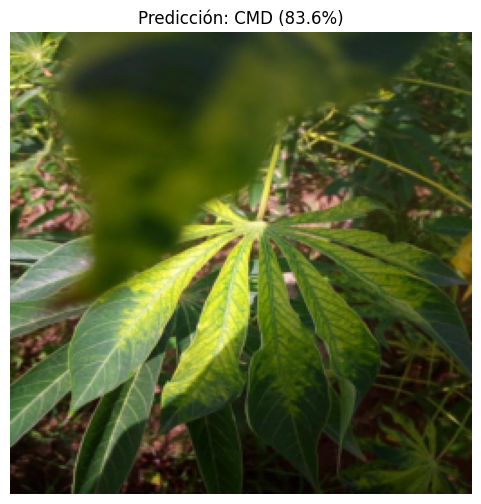

('CMD', np.float32(0.8356845))

In [ ]:
def predict_image(model_path, image_path, class_names, img_size=IMG_SIZE):
    model_ = tf.keras.models.load_model(model_path)
    img = Image.open(image_path).convert('RGB').resize(img_size, Image.BILINEAR)   # mismo preprocesamiento que en el entrenamiento
    img_array = np.array(img, dtype=np.float32) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    preds = model_.predict(img_array, verbose=0)
    predicted = class_names[np.argmax(preds[0])]
    conf = np.max(preds[0])

    # Top 3
    top3_idx = np.argsort(preds[0])[-3:][::-1]
    print(f"Predicción: {predicted} — {CLASS_DESCRIPTIONS[predicted]} ({conf:.1%})")
    for idx in top3_idx:
        print(f"  {class_names[idx]}: {preds[0][idx]:.1%}")

    # Visualizar
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Predicción: {predicted} ({conf:.1%})", fontsize=12)
    plt.axis('off')
    plt.show()

    return predicted, conf

# Ejemplo: predecir una imagen ORIGINAL (800x600) del conjunto de test
sample_name = test_df.iloc[0]['image_id']
print(f"Clase real: {test_df.iloc[0]['class_name']}")
predict_image('models/production/model_v1.keras', os.path.join(data_dir, sample_name), class_names)

### 12.3 API REST con Flask (`/predict`)
Escribimos el servicio en un archivo independiente `app.py`, que puede ejecutarse en cualquier servidor (local, Render, Railway, una VM en la nube...).

| Endpoint | Método | Descripción |
|---|---|---|
| `/` | GET | Página simple para subir una foto y ver el diagnóstico |
| `/health` | GET | Verifica que el servicio esté activo |
| `/predict` | POST | Recibe una imagen (`file`) y devuelve la clase, la confianza, el top 3 y una recomendación en JSON |

In [ ]:
%%writefile app.py
# API REST para el diagnóstico de enfermedades de la yuca
import io, json
import numpy as np
from PIL import Image
from flask import Flask, request, jsonify
import tensorflow as tf

MODEL_PATH = 'models/production/model_v1.keras'
with open('models/production/class_names.json', encoding='utf-8') as f:
    INFO = json.load(f)
CLASS_NAMES = INFO['class_names']
DESCRIPTIONS = INFO['descriptions']
IMG_SIZE = tuple(INFO['img_size'])

# Recomendaciones orientativas (confirmar siempre con un técnico agrícola)
RECOMENDACIONES = {
    'CBB': 'Enfermedad bacteriana: retirar y quemar las plantas afectadas, usar esquejes sanos y desinfectar herramientas.',
    'CBSD': 'Enfermedad viral (transmitida por mosca blanca): eliminar plantas infectadas y usar material de siembra limpio o variedades tolerantes.',
    'CGM': 'Asociado al ácaro verde: vigilar la plaga y consultar opciones de control biológico con un técnico.',
    'CMD': 'Enfermedad viral (transmitida por mosca blanca): eliminar plantas infectadas, controlar el vector y sembrar variedades resistentes.',
    'Healthy': 'La hoja se ve sana. Continuar con el monitoreo periódico del cultivo.',
}

app = Flask(__name__)
MODEL = tf.keras.models.load_model(MODEL_PATH)

def preprocess(file_bytes):
    img = Image.open(io.BytesIO(file_bytes)).convert('RGB').resize(IMG_SIZE, Image.BILINEAR)
    return (np.array(img, dtype=np.float32) / 255.0)[np.newaxis]

@app.route('/', methods=['GET'])
def index():
    return '''<h2>🌿 Diagnóstico de enfermedades de la yuca</h2>
              <form action="/predict" method="post" enctype="multipart/form-data">
                <input type="file" name="file" accept="image/*" required>
                <button type="submit">Diagnosticar</button>
              </form>'''

@app.route('/health', methods=['GET'])
def health():
    return jsonify({'status': 'ok', 'model': MODEL.name, 'classes': CLASS_NAMES})

@app.route('/predict', methods=['POST'])
def predict():
    if 'file' not in request.files:
        return jsonify({'error': 'Envíe una imagen en el campo "file"'}), 400
    try:
        img_array = preprocess(request.files['file'].read())
    except Exception:
        return jsonify({'error': 'El archivo no es una imagen válida'}), 400

    predictions = MODEL.predict(img_array, verbose=0)[0]
    idx = int(np.argmax(predictions))
    predicted_class = CLASS_NAMES[idx]
    top3 = np.argsort(predictions)[::-1][:3]
    return jsonify({
        'class': predicted_class,
        'description': DESCRIPTIONS[predicted_class],
        'confidence': round(float(predictions[idx]), 4),
        'top3': [{'class': CLASS_NAMES[i], 'probability': round(float(predictions[i]), 4)} for i in top3],
        'recommendation': RECOMENDACIONES[predicted_class],
    })

if __name__ == '__main__':
    app.run(host='0.0.0.0', port=5000)

Writing app.py


### 12.4 Levantar la API y consumirla
Iniciamos `app.py` en segundo plano (en CPU, para no competir por la GPU) y la consumimos con `requests`, igual que lo haría una app móvil o una página web.

In [ ]:
import subprocess, requests

# Iniciar el servidor Flask en segundo plano
api_env = dict(os.environ, CUDA_VISIBLE_DEVICES='')   # la API corre en CPU
api_log = open('experiments/api.log', 'w')
api_process = subprocess.Popen(['python', 'app.py'], stdout=api_log, stderr=subprocess.STDOUT, env=api_env)

# Esperar a que cargue el modelo
API_URL = 'http://127.0.0.1:5000'
for _ in range(60):
    try:
        if requests.get(f'{API_URL}/health', timeout=2).status_code == 200:
            break
    except requests.exceptions.ConnectionError:
        time.sleep(2)
else:
    print(open('experiments/api.log').read()[-2000:])
    raise RuntimeError("La API no respondió en 2 minutos; revise el log de arriba.")
print("Health check:", requests.get(f'{API_URL}/health').json())

Health check: {'classes': ['CBB', 'CBSD', 'CGM', 'CMD', 'Healthy'], 'model': 'transfer_efficientnetb0', 'status': 'ok'}


In [ ]:
# Consumir el endpoint /predict con imágenes ORIGINALES de test (una por clase)
for cls in class_names:
    row = test_df[test_df['class_name'] == cls].iloc[0]
    with open(os.path.join(data_dir, row['image_id']), 'rb') as f:
        resp = requests.post(f'{API_URL}/predict', files={'file': f})
    r = resp.json()
    estado = '✅' if r['class'] == cls else '❌'
    print(f"{estado} Real: {cls:<8} → API: {r['class']:<8} ({r['confidence']:.1%}) | {r['recommendation'][:60]}...")

print("\nRespuesta JSON completa del último ejemplo:")
print(json.dumps(r, indent=2, ensure_ascii=False))

❌ Real: CBB      → API: CBSD     (44.9%) | Enfermedad viral (transmitida por mosca blanca): eliminar pl...
❌ Real: CBSD     → API: Healthy  (56.0%) | La hoja se ve sana. Continuar con el monitoreo periódico del...
✅ Real: CGM      → API: CGM      (86.1%) | Asociado al ácaro verde: vigilar la plaga y consultar opcion...
✅ Real: CMD      → API: CMD      (83.6%) | Enfermedad viral (transmitida por mosca blanca): eliminar pl...
✅ Real: Healthy  → API: Healthy  (94.3%) | La hoja se ve sana. Continuar con el monitoreo periódico del...

Respuesta JSON completa del último ejemplo:
{
  "class": "Healthy",
  "confidence": 0.9426,
  "description": "Hoja sana",
  "recommendation": "La hoja se ve sana. Continuar con el monitoreo periódico del cultivo.",
  "top3": [
    {
      "class": "Healthy",
      "probability": 0.9426
    },
    {
      "class": "CGM",
      "probability": 0.0195
    },
    {
      "class": "CBB",
      "probability": 0.0135
    }
  ]
}


---
## 🌍 12.5 Validación Externa: Dataset Independiente de la India

El modelo se entrenó con fotos de **Uganda**. Para saber si realmente sirve en **otros lugares** (como la selva peruana), lo evaluamos con un dataset **totalmente independiente**, tomado en otro país, otra época y con otras cámaras, **sin volver a entrenarlo**. A esto se le llama **validación externa**: mide la capacidad de **generalización** del modelo frente a un **cambio de dominio**.

**Dataset:** *Cassava Leaf Disease Dataset* — Divyanth, L. G., Soni, P. & Machavaram, R. (2021). Mendeley Data, V1. https://doi.org/10.17632/3832tx2cb2.1 (licencia CC BY 4.0)
- Fotos RGB de **512×512** tomadas a mano en **campos comerciales del oeste de Tamil Nadu (India)**, IIT Kharagpur.
- **3 clases:** hoja sana, añublo bacteriano (CBB) y virus del mosaico de la yuca (CMV).

| Clase en el dataset de la India | Clase en nuestro modelo |
|---|---|
| Healthy | `Healthy` |
| Cassava Bacterial Blight (CBB) | `CBB` |
| Cassava Mosaic Virus (CMV) | `CMD` (Cassava Mosaic Disease, causada por ese virus) |

El modelo conoce **5 clases**, pero este dataset solo tiene **3**: si el modelo predice CBSD o CGM en una foto de la India, cuenta como error. Por eso reportamos también una versión **"restringida a 3 clases"** (elegir la más probable solo entre CBB, CMD y Healthy) para separar los dos tipos de error.

> 💡 La misma sección sirve para fotos de **Junín** cuando se consigan: basta con subir un zip con carpetas `Healthy`, `CBB`, `CMD`, etc.

In [ ]:
# 1) Obtener el dataset de la India (descarga directa de Mendeley o subir el zip manualmente)
import zipfile, requests

EXT_DIR = f'{PROJECT_DIR}/data/externo_india'
ZIP_EXT = f'{PROJECT_DIR}/data/3832tx2cb2-1.zip'
URL_MENDELEY = 'https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/3832tx2cb2-1.zip'

def extraer_zip_recursivo(zip_path, destino):
    # Extrae el zip y también los zips que vengan dentro (Mendeley suele anidarlos)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(destino)
    for root, _, files_ in os.walk(destino):
        for f_ in files_:
            if f_.lower().endswith('.zip'):
                interno = os.path.join(root, f_)
                extraer_zip_recursivo(interno, os.path.splitext(interno)[0])
                os.remove(interno)

if not os.path.exists(EXT_DIR):
    # ¿Ya está el zip? (por ejemplo, subido con el panel de archivos de Colab a /content)
    for candidato in ['/content/3832tx2cb2-1.zip', ZIP_EXT]:
        if os.path.exists(candidato) and zipfile.is_zipfile(candidato):
            if candidato != ZIP_EXT:
                shutil.copy(candidato, ZIP_EXT)
            print(f"Usando el zip encontrado en {candidato}")
            break
    else:
        try:
            print("Descargando desde Mendeley Data...")
            r = requests.get(URL_MENDELEY, timeout=120)
            r.raise_for_status()
            with open(ZIP_EXT, 'wb') as f_:
                f_.write(r.content)
            assert zipfile.is_zipfile(ZIP_EXT)
        except Exception as e:
            print(f"⚠️ No se pudo descargar automáticamente ({type(e).__name__}).")
            print("Suba el archivo 3832tx2cb2-1.zip (descargado de Mendeley Data):")
            from google.colab import files
            subido = files.upload()
            shutil.move(list(subido.keys())[0], ZIP_EXT)
    extraer_zip_recursivo(ZIP_EXT, EXT_DIR)
    print("✅ Dataset extraído en", EXT_DIR)

Descargando desde Mendeley Data...
⚠️ No se pudo descargar automáticamente (HTTPError).
Suba el archivo 3832tx2cb2-1.zip (descargado de Mendeley Data):


Saving 3832tx2cb2-1.zip to 3832tx2cb2-1.zip
✅ Dataset extraído en /content/proyecto_cassava/data/externo_india


Imágenes con clase reconocida: 228

Carpeta original → clase asignada:
carpeta                                                                clase_real
3832tx2cb2-1/cassava leaf disease dataset/Cassava CB (Cassava Blight)  CBB           49
3832tx2cb2-1/cassava leaf disease dataset/Cassava CM (Cassava Mosaic)  CMD           88
3832tx2cb2-1/cassava leaf disease dataset/Cassava Healthy leaf         Healthy       91


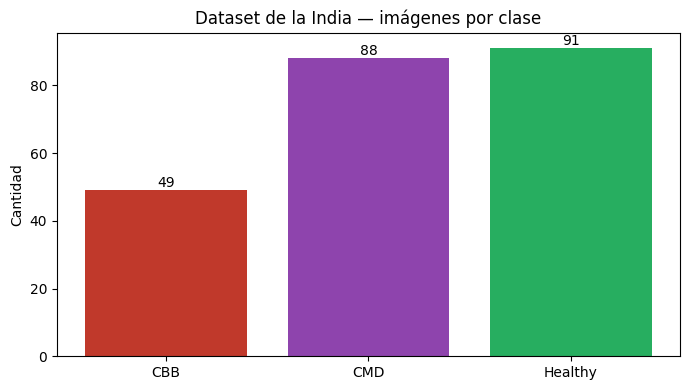


Imágenes idénticas a las del dataset de entrenamiento (Uganda): 0 → debe ser 0 para una validación externa válida


In [ ]:
# 2) Inventario y mapeo de las carpetas del dataset a las clases de nuestro modelo
def mapear_clase(texto):
    t = texto.lower()
    if 'healthy' in t or 'sana' in t:
        return 'Healthy'
    if 'cbb' in t or 'bacterial' in t or 'blight' in t:
        return 'CBB'
    if 'cmv' in t or 'cmd' in t or 'mosaic' in t:
        return 'CMD'
    return None

registros, sin_mapear = [], Counter()
for root, _, files_ in os.walk(EXT_DIR):
    if '__MACOSX' in root:
        continue
    carpeta = os.path.relpath(root, EXT_DIR)
    for f_ in files_:
        if not f_.lower().endswith(('.jpg', '.jpeg', '.png', '.webp', '.bmp')):
            continue
        clase = mapear_clase(carpeta) or mapear_clase(f_)   # primero por carpeta, si no por nombre de archivo
        if clase is None:
            sin_mapear[carpeta] += 1
            continue
        registros.append({'archivo': os.path.join(root, f_), 'carpeta': carpeta, 'clase_real': clase})

ext_df = pd.DataFrame(registros)
print(f"Imágenes con clase reconocida: {len(ext_df)}")
print("\nCarpeta original → clase asignada:")
print(ext_df.groupby(['carpeta', 'clase_real']).size().to_string())
if sin_mapear:
    print("\n⚠️ Imágenes en carpetas sin clase reconocida (no se usan):")
    for c_, n in sin_mapear.items():
        print(f"  {c_}: {n}")

# Distribución por clase
dist_ext = ext_df['clase_real'].value_counts().reindex(['CBB', 'CMD', 'Healthy']).fillna(0).astype(int)
plt.figure(figsize=(7, 4))
bars = plt.bar(dist_ext.index, dist_ext.values, color=['#c0392b', '#8e44ad', '#27ae60'])
for b, v in zip(bars, dist_ext.values):
    plt.text(b.get_x() + b.get_width()/2, v, str(v), ha='center', va='bottom')
plt.title('Dataset de la India — imágenes por clase'); plt.ylabel('Cantidad')
plt.tight_layout(); plt.show()

# Control de fuga de datos: ¿alguna imagen es idéntica a las del entrenamiento?
with ThreadPoolExecutor(max_workers=8) as ex:
    md5_ext = list(ex.map(file_md5, ext_df['archivo']))
print(f"\nImágenes idénticas a las del dataset de entrenamiento (Uganda): "
      f"{sum(m in set(df['md5']) for m in md5_ext)} → debe ser 0 para una validación externa válida")

In [ ]:
# 3) Predecir con el modelo final (mismo preprocesamiento que en el entrenamiento)
from PIL import ImageOps
UMBRAL_CONFIANZA = 0.50   # por debajo de esto el diagnóstico se reporta como "Incierto"
CLASES_INDIA = ['CBB', 'CMD', 'Healthy']
idx_india = [class_names.index(c) for c in CLASES_INDIA]

def preparar_imagen(path):
    img = ImageOps.exif_transpose(Image.open(path))          # corrige fotos de celular giradas
    img = img.convert('RGB').resize(IMG_SIZE, Image.BILINEAR)
    return np.array(img, dtype=np.float32) / 255.0

modelo_final = tf.keras.models.load_model('models/production/model_v1.keras')
X_ext = np.stack([preparar_imagen(p) for p in ext_df['archivo']])
probs_ext = modelo_final.predict(X_ext, batch_size=32, verbose=0)

ext_df['pred'] = [class_names[i] for i in probs_ext.argmax(axis=1)]
ext_df['confianza'] = probs_ext.max(axis=1)
ext_df['diagnostico'] = np.where(ext_df['confianza'] >= UMBRAL_CONFIANZA,
                                 ext_df['pred'], 'Incierto (consultar técnico)')
# Predicción restringida: la clase más probable SOLO entre las 3 que existen en este dataset
ext_df['pred_3clases'] = [CLASES_INDIA[i] for i in probs_ext[:, idx_india].argmax(axis=1)]

ext_df.to_csv('experiments/validacion_externa_india.csv', index=False)
print(f"Predicciones con confianza ≥ {UMBRAL_CONFIANZA:.0%}: {(ext_df['confianza'] >= UMBRAL_CONFIANZA).mean():.1%}")
print("\n¿Qué predijo el modelo para cada clase real?")
print(pd.crosstab(ext_df['clase_real'], ext_df['pred'], margins=True, margins_name='Total'))

Predicciones con confianza ≥ 50%: 94.7%

¿Qué predijo el modelo para cada clase real?
pred        CBB  CBSD  CGM  CMD  Healthy  Total
clase_real                                     
CBB          10     1    1   33        4     49
CMD           0     5   24   59        0     88
Healthy       0     0    0    0       91     91
Total        10     6   25   92       95    228


=== Dataset de la India (5 clases posibles) ===
              precision    recall  f1-score   support

         CBB     1.0000    0.2041    0.3390        49
         CMD     0.6413    0.6705    0.6556        88
     Healthy     0.9579    1.0000    0.9785        91

   micro avg     0.8122    0.7018    0.7529       228
   macro avg     0.8664    0.6248    0.6577       228
weighted avg     0.8448    0.7018    0.7164       228



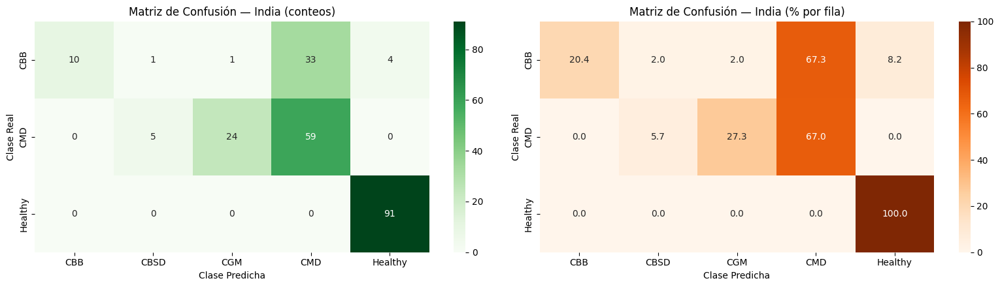

                            Conjunto  Imágenes  Accuracy  F1 macro (3 clases)
Test Uganda (solo CBB, CMD, Healthy)      2523    0.8395               0.7553
           India — 5 clases posibles       228    0.7018               0.6577
      India — restringido a 3 clases       228    0.8158               0.7134


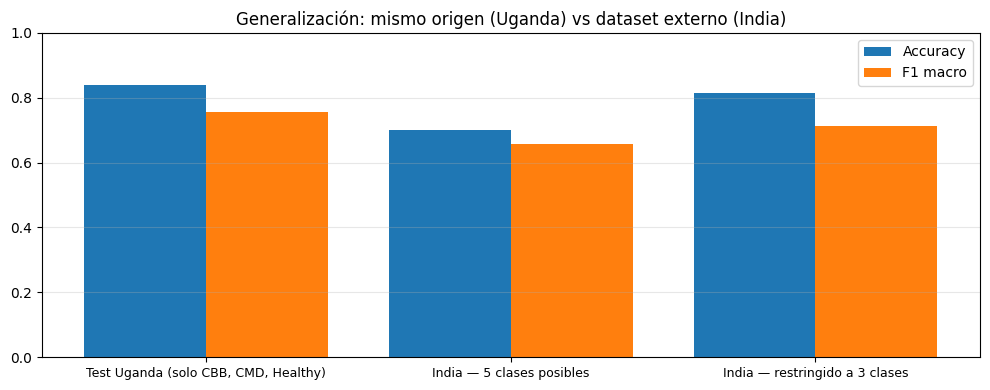

In [ ]:
# 4) Métricas y comparación con el test de Uganda
yx_true = ext_df['clase_real'].map(class_names.index).values
yx_pred = ext_df['pred'].map(class_names.index).values
yx_pred3 = ext_df['pred_3clases'].map(class_names.index).values

print("=== Dataset de la India (5 clases posibles) ===")
print(classification_report(yx_true, yx_pred, labels=idx_india, target_names=CLASES_INDIA,
                            digits=4, zero_division=0))

# Matriz de confusión: filas = 3 clases reales, columnas = 5 clases que puede predecir el modelo
cm_x = confusion_matrix(yx_true, yx_pred, labels=range(NUM_CLASSES))[idx_india]
cm_x_pct = cm_x / cm_x.sum(axis=1, keepdims=True) * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.heatmap(cm_x, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=CLASES_INDIA, ax=axes[0])
axes[0].set_title('Matriz de Confusión — India (conteos)')
sns.heatmap(cm_x_pct, annot=True, fmt='.1f', cmap='Oranges', xticklabels=class_names, yticklabels=CLASES_INDIA, ax=axes[1])
axes[1].set_title('Matriz de Confusión — India (% por fila)')
for a in axes:
    a.set_ylabel('Clase Real'); a.set_xlabel('Clase Predicha')
plt.tight_layout()
plt.savefig('experiments/validacion_externa_india_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

# Comparación justa: en Uganda también usamos solo las imágenes de test de esas 3 clases
mask_u = np.isin(y_true, idx_india)
comparacion = pd.DataFrame({
    'Conjunto': ['Test Uganda (solo CBB, CMD, Healthy)', 'India — 5 clases posibles', 'India — restringido a 3 clases'],
    'Imágenes': [int(mask_u.sum()), len(ext_df), len(ext_df)],
    'Accuracy': [accuracy_score(y_true[mask_u], y_pred[mask_u]),
                 accuracy_score(yx_true, yx_pred), accuracy_score(yx_true, yx_pred3)],
    'F1 macro (3 clases)': [f1_score(y_true[mask_u], y_pred[mask_u], labels=idx_india, average='macro', zero_division=0),
                            f1_score(yx_true, yx_pred, labels=idx_india, average='macro', zero_division=0),
                            f1_score(yx_true, yx_pred3, labels=idx_india, average='macro', zero_division=0)],
})
print(comparacion.round(4).to_string(index=False))
comparacion.to_csv('experiments/validacion_externa_comparacion.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 4))
xs = np.arange(len(comparacion))
ax.bar(xs - 0.2, comparacion['Accuracy'], 0.4, label='Accuracy')
ax.bar(xs + 0.2, comparacion['F1 macro (3 clases)'], 0.4, label='F1 macro')
ax.set_xticks(xs); ax.set_xticklabels(comparacion['Conjunto'], fontsize=9)
ax.set_ylim(0, 1); ax.legend(); ax.grid(True, alpha=0.3, axis='y')
ax.set_title('Generalización: mismo origen (Uganda) vs dataset externo (India)')
plt.tight_layout()
plt.savefig('experiments/validacion_externa_comparacion.png', dpi=150, bbox_inches='tight')
plt.show()

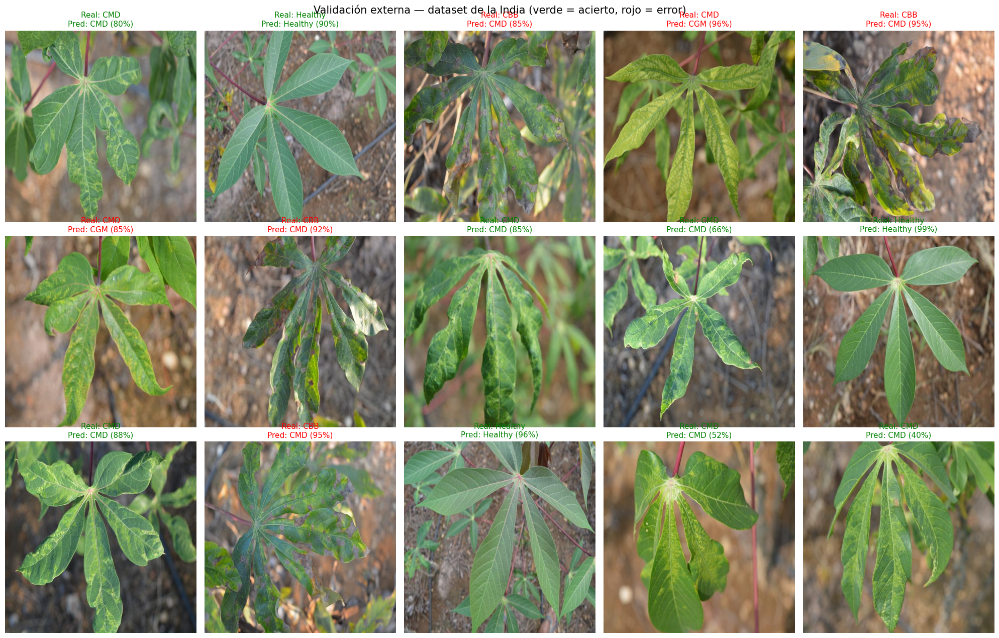

In [ ]:
# 5) Ejemplos: aciertos y errores en el dataset de la India
n_mostrar = min(15, len(ext_df))
muestra = ext_df.sample(n_mostrar, random_state=SEED)
filas = int(np.ceil(n_mostrar / 5))
fig, axes = plt.subplots(filas, 5, figsize=(20, 4.3 * filas), squeeze=False)
for ax in axes.flat:
    ax.axis('off')
for ax, (_, r) in zip(axes.flat, muestra.iterrows()):
    ax.imshow(ImageOps.exif_transpose(Image.open(r['archivo'])).convert('RGB'))
    color = 'green' if r['pred'] == r['clase_real'] else 'red'
    ax.set_title(f"Real: {r['clase_real']}\nPred: {r['pred']} ({r['confianza']:.0%})", fontsize=11, color=color)
plt.suptitle('Validación externa — dataset de la India (verde = acierto, rojo = error)', fontsize=15)
plt.tight_layout()
plt.savefig('experiments/validacion_externa_india_muestras.png', dpi=150, bbox_inches='tight')
plt.show()

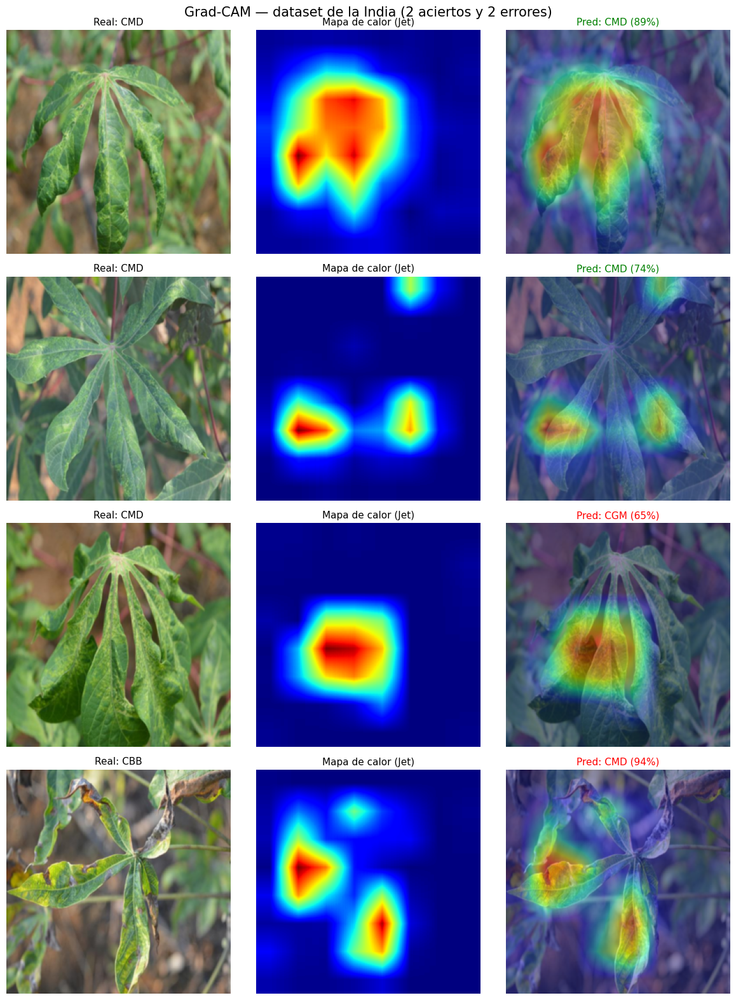

In [ ]:
# 6) Grad-CAM en fotos de la India: ¿el modelo mira las lesiones o el fondo?
last_conv_final = get_last_conv_layer_name(modelo_final)
casos = pd.concat([
    ext_df[ext_df['pred'] == ext_df['clase_real']].sample(min(2, (ext_df['pred'] == ext_df['clase_real']).sum()), random_state=SEED),
    ext_df[ext_df['pred'] != ext_df['clase_real']].sample(min(2, (ext_df['pred'] != ext_df['clase_real']).sum()), random_state=SEED),
])
fig, axes = plt.subplots(len(casos), 3, figsize=(12, 4 * len(casos)), squeeze=False)
for row, (_, r) in zip(axes, casos.iterrows()):
    show_gradcam(r['archivo'], modelo_final, last_conv_final, class_names.index(r['clase_real']), row)
plt.suptitle('Grad-CAM — dataset de la India (2 aciertos y 2 errores)', fontsize=15)
plt.tight_layout()
plt.savefig('experiments/validacion_externa_india_gradcam.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# 7) Flujo completo de despliegue: enviar fotos de la India a la API, como lo haría una app
for _, r in ext_df.groupby('clase_real').head(2).iterrows():
    with open(r['archivo'], 'rb') as f_:
        resp = requests.post(f'{API_URL}/predict', files={'file': f_}).json()
    estado = '✅' if resp['class'] == r['clase_real'] else '❌'
    print(f"{estado} Real: {r['clase_real']:<8} → API: {resp['class']:<8} ({resp['confidence']:.0%}) | "
          f"{resp['recommendation'][:60]}...")

❌ Real: CBB      → API: CMD      (89%) | Enfermedad viral (transmitida por mosca blanca): eliminar pl...
✅ Real: CBB      → API: CBB      (89%) | Enfermedad bacteriana: retirar y quemar las plantas afectada...
✅ Real: Healthy  → API: Healthy  (96%) | La hoja se ve sana. Continuar con el monitoreo periódico del...
✅ Real: Healthy  → API: Healthy  (97%) | La hoja se ve sana. Continuar con el monitoreo periódico del...
✅ Real: CMD      → API: CMD      (85%) | Enfermedad viral (transmitida por mosca blanca): eliminar pl...
✅ Real: CMD      → API: CMD      (66%) | Enfermedad viral (transmitida por mosca blanca): eliminar pl...


### 📝 Análisis de la validación externa
**¿El modelo identifica las enfermedades en fotos de la India?** Parcialmente. Con las **228 fotos** (49 CBB, 88 CMD, 91 Healthy) acertó **160, un 70.2%** (F1 macro 0.658 sobre las 3 clases). Se verificó que **ninguna foto es idéntica** a las del entrenamiento.

| Conjunto | Imágenes | Accuracy | F1 macro (3 clases) |
|---|---|---|---|
| Test Uganda (solo CBB, CMD, Healthy) | 2,523 | 84.0% | 0.755 |
| India — 5 clases posibles | 228 | 70.2% | 0.658 |
| India — restringido a 3 clases | 228 | 81.6% | 0.713 |

- **Caída de rendimiento:** la accuracy baja de **84.0% (Uganda) a 70.2% (India)**, unos 14 puntos. La versión de 192 px había obtenido 71.9% en la India: **mejorar la resolución subió el rendimiento en Uganda, pero no en la India**.
- **Por clase:** **Healthy 91/91 (100%)**; **CMD 59/88 (67%)**, con errores hacia CGM (24) y CBSD (5); **CBB 10/49 (20%)**, que se confundió sobre todo con **CMD (33)**. Cuando el modelo dijo "CBB", siempre acertó (precisión 100%), pero casi nunca lo dice.
- **Tipos de error:** de los 68 errores, 31 (46%) fueron CBSD o CGM, clases que este dataset no tiene; si se restringe la decisión a las 3 clases existentes, la accuracy sube a **81.6%**. El error más grave ahora es CBB → CMD.
- **Confianza:** el 94.7% de las predicciones superó el 50%. El resto se mostraría como "Incierto" en la app.
- **Grad-CAM:** en las fotos de la India el modelo también se enfoca en los lóbulos de la hoja con síntomas, no en el suelo. En el error CMD → CGM (65%) mira la zona moteada correcta pero la interpreta como CGM; en el error CBB → CMD (94%) mira hojas amarillentas y enrolladas, que el modelo asocia con el mosaico.

**Por qué baja (cambio de dominio):** otras variedades de yuca, fotos de **una sola hoja en primer plano a 512×512** (frente a fotos de planta completa a 800×600 en Uganda), otra cámara, otra iluminación y otros fondos. En la India el añublo bacteriano se ve como hojas amarillentas y marchitas, un aspecto que en Uganda corresponde más a CMD.

**Conclusión y propuesta:** un modelo entrenado con fotos de un solo país **no se puede usar directamente en otro sin validarlo**. Reconoce muy bien las hojas sanas, pero pierde precisión al distinguir enfermedades, sobre todo CBB. Para usarlo en **Junín** habría que **validarlo con fotos locales** y hacer **fine-tuning** con imágenes etiquetadas de la región, agregando como nuevas clases las enfermedades propias de la zona.


In [ ]:
# Al terminar: detener la API (y el túnel de ngrok si se abrió)
try:
    ngrok.kill()
except NameError:
    pass
api_process.terminate()
api_log.close()
print("🛑 API detenida")

🛑 API detenida


---
## 🌐 12.6 Despliegue Web Público (Hugging Face Spaces — página estática)

Todo lo anterior vive dentro de Colab y desaparece al cerrar la sesión. Para que **cualquier persona** pueda usar el modelo desde su celular o computadora, lo publicamos como **página web permanente y gratuita** en Hugging Face Spaces.

Los Spaces gratuitos solo permiten páginas **estáticas** (sin servidor Python). Por eso la inferencia se hace **en el navegador del usuario** con **TensorFlow.js**: la página descarga el modelo convertido al formato *graph model* de TF.js (pesos Float16, ~7.8 MB) y lo ejecuta en el propio dispositivo. Ventajas: la foto **no sale del dispositivo** y la página nunca "se duerme".

| Archivo | Para qué sirve |
|---|---|
| `index.html` | Página: subir/tomar foto, preprocesar (256×256, [0,1]), ejecutar el modelo y mostrar diagnóstico, confianza, recomendación y probabilidades |
| `model.json` + `group1-shard*.bin` | Modelo final en formato TensorFlow.js (Float16) |
| `class_names.json` | Nombres de clases, descripciones y tamaño de entrada |
| `model.tflite` | Modelo TFLite Float16 (7.8 MB) para la app móvil; la página web no lo usa |

> La **API REST** del proyecto es la de Flask (12.4); la página web es un despliegue adicional orientado al usuario final.

> 🛠️ **Problema de despliegue resuelto:** la primera versión de la página ejecutaba el `model.tflite` con *tfjs-tflite* (intérprete TFLite experimental en WebAssembly). Funcionaba con el modelo de 192 px, pero con el de 256 px el intérprete abortaba al predecir (`Aborted()`), aunque el modelo cargaba bien. Se migró a **TensorFlow.js**, la librería oficial y estable, convirtiendo el modelo con `tensorflowjs_converter`. El `model.tflite` se mantiene para la app móvil.


In [ ]:
os.makedirs('despliegue_web', exist_ok=True)   # carpeta del despliegue web

In [ ]:
%%writefile despliegue_web/index.html
<!doctype html>
<html lang="es">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Diagnóstico de Yuca</title>
<!-- TensorFlow.js (versión fija). El modelo se carga en formato TF.js (model.json + archivos .bin) -->
<script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@4.22.0/dist/tf.min.js"></script>
<style>
  :root { --bg:#f4f7f2; --card:#ffffff; --text:#1f2a1c; --muted:#5d6b58; --line:#dde5d8;
          --brand:#2f7d32; --on-brand:#ffffff; --brand-soft:#e3f1e2; --warn:#a15c00; --warn-soft:#fff3df; --bar:#cfe3cd; --err:#c62828; }
  @media (prefers-color-scheme: dark) {
    :root { --bg:#131811; --card:#1c231a; --text:#e6eee2; --muted:#a3b19d; --line:#2e392b;
            --brand:#7cc47f; --on-brand:#0f1a0e; --brand-soft:#223322; --warn:#ffb950; --warn-soft:#3a2b14; --bar:#2f4a2f; --err:#ff8a80; }
  }
  * { box-sizing: border-box; }
  body { margin:0; font-family: system-ui, -apple-system, "Segoe UI", Roboto, sans-serif;
         background:var(--bg); color:var(--text); line-height:1.5; }
  main { max-width: 640px; margin: 0 auto; padding: 24px 16px 48px; }
  h1 { font-size: 1.6rem; margin: 0 0 4px; }
  .sub { color: var(--muted); margin: 0 0 20px; }
  .card { background:var(--card); border:1px solid var(--line); border-radius:16px; padding:20px; margin-bottom:16px; }
  .status { display:flex; align-items:center; gap:10px; font-size:.95rem; color:var(--muted); margin-bottom:14px; }
  .dot { width:10px; height:10px; border-radius:50%; background:var(--warn); flex:none; }
  .status.ok .dot { background: var(--brand); }
  .status.error { color: var(--err); }
  .status.error .dot { background: var(--err); }
  .drop { display:flex; flex-direction:column; align-items:center; justify-content:center; gap:8px;
          border:2px dashed var(--line); border-radius:12px; padding:24px; text-align:center; cursor:pointer; min-height:180px; }
  .drop:hover, .drop.over { border-color: var(--brand); background: var(--brand-soft); }
  .drop img { max-width:100%; max-height:320px; border-radius:8px; }
  .drop span { color: var(--muted); }
  input[type=file] { display:none; }
  button { width:100%; margin-top:14px; padding:14px; font-size:1rem; font-weight:600; border:0; border-radius:10px;
           background:var(--brand); color:var(--on-brand); cursor:pointer; }
  button:disabled { opacity:.5; cursor:not-allowed; }
  .result h2 { margin:0; font-size:1.3rem; }
  .desc { color: var(--muted); margin: 2px 0 12px; }
  .conf { font-weight:700; color: var(--brand); }
  .alert { background:var(--warn-soft); color:var(--warn); border-radius:10px; padding:10px 12px; margin:12px 0; font-size:.95rem; }
  .rec { background:var(--brand-soft); border-radius:10px; padding:12px; margin-top:12px; }
  .row { margin: 8px 0; }
  .row .lbl { display:flex; justify-content:space-between; font-size:.92rem; gap:8px; }
  .track { height:10px; background:var(--line); border-radius:6px; overflow:hidden; margin-top:4px; }
  .fill { height:100%; background:var(--bar); }
  .row.top .fill { background: var(--brand); }
  .foot { color: var(--muted); font-size:.85rem; text-align:center; }
  .hidden { display:none; }
  .error { color: var(--err); margin-top:10px; }
</style>
</head>
<body>
<main>
  <h1>🌿 Diagnóstico de enfermedades de la yuca</h1>
  <p class="sub">Sube o toma una foto de una hoja de yuca y el modelo CNN estimará si está sana o qué enfermedad presenta.
     El análisis se hace <strong>en tu propio dispositivo</strong>: la foto no se envía a ningún servidor.</p>

  <div class="card">
    <div class="status" id="status"><span class="dot"></span><span id="statusText">Cargando el modelo (≈ 6 MB)...</span></div>
    <label class="drop" id="drop" for="file">
      <img id="preview" class="hidden" alt="Foto seleccionada">
      <strong id="dropText">📷 Toca para tomar o elegir una foto</strong>
      <span id="dropHint">o arrastra una imagen aquí (JPG o PNG)</span>
    </label>
    <input type="file" id="file" accept="image/*">
    <button id="btn" disabled>Diagnosticar</button>
    <div id="error" class="error hidden"></div>
  </div>

  <div class="card result hidden" id="result">
    <h2 id="rClass"></h2>
    <div class="desc" id="rDesc"></div>
    <div>Confianza: <span class="conf" id="rConf"></span></div>
    <div class="alert hidden" id="rWarn">⚠️ Confianza baja: el resultado es incierto. Toma otra foto con buena luz o consulta a un técnico agrícola.</div>
    <div class="rec"><strong>Recomendación:</strong> <span id="rRec"></span></div>
    <h3 style="margin:18px 0 4px;font-size:1rem">Probabilidad por clase</h3>
    <div id="bars"></div>
  </div>

  <p class="foot">Proyecto académico — IS056B Ingeniería del Conocimiento, UNCP.<br>
  Modelo CNN (TensorFlow.js, Float16) entrenado con el dataset Cassava Leaf Disease (Uganda).
  Resultado orientativo: confirmar siempre con un especialista agrícola.</p>
</main>
<canvas id="canvas" class="hidden"></canvas>
<script>
  const VERSION = '256-tfjs';          // cambiar este texto cada vez que se suba un modelo nuevo (evita la caché)
  const UMBRAL_CONFIANZA = 0.50;
  const RECOMENDACIONES = {
    CBB: 'Enfermedad bacteriana: retirar y quemar las plantas afectadas, usar esquejes sanos y desinfectar herramientas.',
    CBSD: 'Enfermedad viral (transmitida por mosca blanca): eliminar plantas infectadas y usar material de siembra limpio o variedades tolerantes.',
    CGM: 'Asociado al ácaro verde: vigilar la plaga y consultar opciones de control biológico con un técnico.',
    CMD: 'Enfermedad viral (transmitida por mosca blanca): eliminar plantas infectadas, controlar el vector y sembrar variedades resistentes.',
    Healthy: 'La hoja se ve sana. Continuar con el monitoreo periódico del cultivo.'
  };

  const $ = id => document.getElementById(id);
  const fileInput = $('file'), drop = $('drop'), preview = $('preview'), btn = $('btn'), errorBox = $('error');
  let modelo = null, info = null, seleccionada = false, tamEntrada = null;

  function estado(texto, tipo) {
    $('status').className = 'status' + (tipo ? ' ' + tipo : '');
    $('statusText').textContent = texto;
  }
  function mostrarError(texto) { errorBox.textContent = texto; errorBox.classList.remove('hidden'); }
  function actualizarBoton() { btn.disabled = !(modelo && seleccionada); }

  // 1) Cargar el modelo TFLite y la información de clases
  (async () => {
    try {
      await tf.ready();
      const [resp, m] = await Promise.all([fetch('class_names.json?v=' + VERSION, { cache: 'no-store' }), tf.loadGraphModel('model.json', { requestInit: { cache: 'no-store' } })]);
      if (!resp.ok) throw new Error('no se encontró class_names.json');
      info = await resp.json();
      modelo = m;
      // El tamaño de entrada se toma del propio modelo (evita desajustes con un class_names.json viejo)
      const forma = modelo.inputs && modelo.inputs[0] && modelo.inputs[0].shape;
      if (forma && forma.length === 4 && forma[1] > 0 && forma[2] > 0) {
        tamEntrada = [forma[2], forma[1]];            // [ancho, alto]
      } else {
        tamEntrada = info.img_size;                   // respaldo: lo que diga class_names.json
      }
      console.log('[yuca] versión', VERSION, '| backend:', tf.getBackend(), '| entrada del modelo:', forma, '| class_names.json:', info.img_size);
      estado('Modelo listo ✔ (entrada ' + tamEntrada[0] + '×' + tamEntrada[1] + ')', 'ok');
      actualizarBoton();
    } catch (err) {
      console.error(err);
      estado('No se pudo cargar el modelo: ' + (err && err.message ? err.message : err), 'error');
    }
  })();

  // 2) Elegir la foto
  function elegir(file) {
    if (!file || !file.type.startsWith('image/')) return;
    preview.src = URL.createObjectURL(file);
    preview.classList.remove('hidden');
    $('dropText').textContent = 'Toca para cambiar la foto';
    $('dropHint').classList.add('hidden');
    seleccionada = true;
    actualizarBoton();
    $('result').classList.add('hidden');
    errorBox.classList.add('hidden');
  }
  fileInput.addEventListener('change', e => elegir(e.target.files[0]));
  ['dragover', 'dragenter'].forEach(ev => drop.addEventListener(ev, e => { e.preventDefault(); drop.classList.add('over'); }));
  ['dragleave', 'drop'].forEach(ev => drop.addEventListener(ev, e => { e.preventDefault(); drop.classList.remove('over'); }));
  drop.addEventListener('drop', e => elegir(e.dataTransfer.files[0]));

  // 3) Diagnosticar: mismo preprocesamiento que en el entrenamiento (RGB, redimensionar, escalar a [0,1])
  btn.addEventListener('click', async () => {
    btn.disabled = true; btn.textContent = 'Analizando...';
    errorBox.classList.add('hidden');
    try {
      await preview.decode();
      const [w, h] = tamEntrada;
      const canvas = $('canvas');
      canvas.width = w; canvas.height = h;
      const ctx = canvas.getContext('2d');
      ctx.imageSmoothingEnabled = true;
      ctx.imageSmoothingQuality = 'high';
      ctx.drawImage(preview, 0, 0, w, h);

      console.log('[yuca] imagen enviada:', w, 'x', h);
      const entrada = tf.tidy(() => tf.expandDims(tf.div(tf.cast(tf.browser.fromPixels(canvas), 'float32'), 255), 0));
      let salida = modelo.predict(entrada);
      if (!(salida instanceof tf.Tensor)) salida = Object.values(salida)[0];
      const probs = Array.from(await salida.data());
      tf.dispose([entrada, salida]);
      mostrar(probs);
    } catch (err) {
      console.error(err);
      mostrarError('No se pudo analizar la imagen: ' + (err && err.message ? err.message : err));
    } finally {
      btn.textContent = 'Diagnosticar';
      actualizarBoton();
    }
  });

  // 4) Mostrar el resultado
  function mostrar(probs) {
    const nombres = info.class_names;
    const orden = probs.map((p, i) => i).sort((a, b) => probs[b] - probs[a]);
    const clase = nombres[orden[0]], conf = probs[orden[0]], incierto = conf < UMBRAL_CONFIANZA;
    const pct = p => (p * 100).toFixed(1) + '%';
    $('rClass').textContent = incierto ? 'Resultado incierto (' + clase + '?)' : clase;
    $('rDesc').textContent = info.descriptions[clase];
    $('rConf').textContent = pct(conf);
    $('rWarn').classList.toggle('hidden', !incierto);
    $('rRec').textContent = RECOMENDACIONES[clase];
    const bars = $('bars');
    bars.innerHTML = '';
    orden.forEach((i, k) => {
      const row = document.createElement('div');
      row.className = 'row' + (k === 0 ? ' top' : '');
      row.innerHTML = '<div class="lbl"><span></span><span></span></div><div class="track"><div class="fill"></div></div>';
      row.querySelector('.lbl span:first-child').textContent = nombres[i] + ' — ' + info.descriptions[nombres[i]];
      row.querySelector('.lbl span:last-child').textContent = pct(probs[i]);
      row.querySelector('.fill').style.width = pct(probs[i]);
      bars.appendChild(row);
    });
    $('result').classList.remove('hidden');
    $('result').scrollIntoView({ behavior: 'smooth' });
  }
</script>
</body>
</html>

Writing despliegue_web/index.html


In [ ]:
# Copiar el modelo liviano y empaquetar la página
shutil.copy('models/production/model_v1_q.tflite', 'despliegue_web/model.tflite')
shutil.copy('models/production/class_names.json', 'despliegue_web/class_names.json')
for viejo in ['app.py', 'requirements.txt', 'Dockerfile', 'README.md']:   # restos de versiones anteriores
    if os.path.exists(f'despliegue_web/{viejo}'):
        os.remove(f'despliegue_web/{viejo}')

!cd despliegue_web && rm -f ../despliegue_web.zip && zip -q -r ../despliegue_web.zip .
print("Archivos del despliegue:")
for f_ in sorted(os.listdir('despliegue_web')):
    print(f"  📄 {f_:<18} {os.path.getsize(os.path.join('despliegue_web', f_))/1024:,.0f} KB")
print(f"\nModelo publicado: {best_name}")
from google.colab import files
files.download('despliegue_web.zip')

Archivos del despliegue:
  📄 class_names.json   0 KB
  📄 index.html         10 KB
  📄 model.tflite       7,962 KB

Modelo publicado: Transfer EfficientNetB0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#### Conversión del modelo a TensorFlow.js (para la página web)
Se exporta el modelo final como SavedModel y se convierte con `tensorflowjs_converter` (pesos Float16). La librería `tensorflowjs` importa `tensorflow_decision_forests`, que no está disponible para el Python de Colab; como solo se usa con modelos de árboles de decisión, se crea un módulo vacío con ese nombre. El resultado (`model.json` + archivos `.bin`) se descarga en `modelo_tfjs.zip`.


In [ ]:
# Convertir el modelo final a TensorFlow.js (formato para la página web)
import os, glob, shutil, subprocess
import tensorflow as tf
from google.colab import files

PROJECT_DIR = '/content/proyecto_cassava'
os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)

# 1) Modelo: el de producción si la sesión sigue activa; si no, desde el respaldo de 256 px
MODEL_PATH = 'models/production/model_v1.keras'
if not os.path.exists(MODEL_PATH):
    ya = glob.glob(f'{PROJECT_DIR}/experiments/checkpoints/transfer_ft_*/best_model.keras')
    if not ya:
        print("Suba el experimentos.zip de 256 px")
        z = list(files.upload().keys())[0]
        subprocess.run(['unzip', '-q', '-o', z, '-d', PROJECT_DIR], check=True)
    MODEL_PATH = sorted(glob.glob(f'{PROJECT_DIR}/experiments/checkpoints/transfer_ft_*/best_model.keras'))[-1]
modelo = tf.keras.models.load_model(MODEL_PATH)
print("Modelo:", MODEL_PATH, "| entrada:", modelo.input_shape)

# 2) Exportar como SavedModel
saved_dir = 'models/saved_model_web'
shutil.rmtree(saved_dir, ignore_errors=True)
modelo.export(saved_dir)

# 3) Convertir a TensorFlow.js (pesos float16, ~8 MB)
!pip install -q --no-deps tensorflowjs
!pip install -q tensorflow_hub

# Módulo vacío: tensorflowjs lo importa, pero solo se usa con modelos de árboles de decisión
site = sysconfig.get_paths()['purelib']
os.makedirs(f'{site}/tensorflow_decision_forests', exist_ok=True)
open(f'{site}/tensorflow_decision_forests/__init__.py', 'w').close()

# Revisar que tensorflowjs cargue; si falta otra dependencia, instalarla sin tocar TensorFlow
tf_mm = '.'.join(tf.__version__.split('.')[:2])
for _ in range(6):
    r = subprocess.run([sys.executable, '-c', 'import tensorflowjs'], capture_output=True, text=True)
    if r.returncode == 0:
        print("✅ tensorflowjs listo")
        break
    m = re.search(r"No module named '([\w\.]+)'", r.stderr)
    if not m:
        print(r.stderr[-2000:]); raise RuntimeError("Error al importar tensorflowjs (ver arriba)")
    falta = m.group(1).split('.')[0]
    print("Instalando dependencia faltante:", falta)
    if falta == 'tf_keras':
        ok = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', f'tf_keras~={tf_mm}.0']).returncode == 0
        if not ok:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', 'tf_keras'], check=True)
    else:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', falta], check=True)

# Convertir (pesos float16, ~8 MB)
out_dir = 'web_tfjs'
shutil.rmtree(out_dir, ignore_errors=True)
cmd = ['tensorflowjs_converter', '--input_format=tf_saved_model',
       '--output_format=tfjs_graph_model', '--quantize_float16=*']
r = subprocess.run(cmd + [saved_dir, out_dir], capture_output=True, text=True)
if r.returncode != 0:
    r = subprocess.run(cmd + ['--signature_name=serve', saved_dir, out_dir], capture_output=True, text=True)
if r.returncode != 0:
    print(r.stderr[-3000:]); raise RuntimeError("La conversión falló (ver arriba)")

# Empaquetar y descargar
subprocess.run('cd web_tfjs && rm -f ../modelo_tfjs.zip && zip -q -r ../modelo_tfjs.zip .', shell=True, check=True)
for f_ in sorted(os.listdir(out_dir)):
    print(f"  📄 {f_:<28} {os.path.getsize(os.path.join(out_dir, f_))/1024:,.0f} KB")
files.download('modelo_tfjs.zip')

Modelo: models/production/model_v1.keras | entrada: (None, 256, 256, 3)
✅ tensorflowjs listo
  📄 group1-shard1of2.bin         4,096 KB
  📄 group1-shard2of2.bin         3,721 KB
  📄 model.json                   342 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 🚀 Publicar o actualizar en Hugging Face Spaces
1. Cuenta gratuita en [huggingface.co](https://huggingface.co) → **New → Space**: nombre `diagnostico-yuca`, SDK **Static**, plantilla **Blank**, **Create Space**.
2. Pestaña **Files → "+ Contribute" → Upload files**: subir `index.html` y `class_names.json` (de `despliegue_web.zip`) y `model.json` + todos los `group1-shard*.bin` (de `modelo_tfjs.zip`) → **Commit changes to main**.
3. Abrir la pestaña **App** (recargar con Ctrl + F5 o en una ventana de incógnito). Debe decir **"Modelo listo ✔ (entrada 256×256)"**.

**Para actualizar el modelo** (por ejemplo, tras reentrenar): volver a ejecutar la conversión a TensorFlow.js y subir el nuevo `model.json`, los `.bin` y `class_names.json`.

Página publicada: https://huggingface.co/spaces/WalkerRD/diagnostico-yuca


In [ ]:
# (Opcional) Guardar los entregables en Google Drive; si falla, descargarlos como zip
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
    DEST = '/content/drive/MyDrive/proyecto_cassava'
    for item in ['models', 'experiments', 'README.md', 'requirements.txt', 'app.py', '.gitignore']:
        src = os.path.join(PROJECT_DIR, item)
        dst = os.path.join(DEST, item)
        if os.path.isdir(src):
            shutil.copytree(src, dst, dirs_exist_ok=True)
        elif os.path.exists(src):
            os.makedirs(DEST, exist_ok=True)
            shutil.copy(src, dst)
    print(f"✅ Entregables copiados a {DEST}")
except Exception as e:
    print(f"⚠️ No se pudo usar Drive ({type(e).__name__}). Descargando los entregables como zip...")
    !cd {PROJECT_DIR} && zip -r -q /content/entregables.zip models experiments README.md requirements.txt app.py .gitignore
    from google.colab import files
    files.download('/content/entregables.zip')

Mounted at /content/drive
✅ Entregables copiados a /content/drive/MyDrive/proyecto_cassava


---
## ✅ Checklist del Pipeline Completo

| # | Fase | Dónde | Estado |
|---|---|---|---|
| 1 | Definición del problema | Ficha de proyecto | ✅ |
| 2 | Selección del dataset + EDA | Distribución, propiedades, muestras, corruptas, duplicados | ✅ |
| 3 | Preprocesamiento + augmentation | División estratificada, `tf.data`, augmentation justificado, class_weight | ✅ |
| 4 | 4 modelos (Baseline, Mejorada, Optimizada + Transfer Learning EfficientNetB0) | Fase 4 | ✅ |
| 5 | Entrenamiento con 5 callbacks | + ExperimentLogger personalizado | ✅ |
| 6 | Evaluación (report + confusión + ROC) | Sobre **test** | ✅ |
| 7 | Análisis de errores | Top confusiones, errores con alta confianza, Grad-CAM, tabla de mejoras | ✅ |
| 8 | Comparación de modelos | Métricas de test vs complejidad | ✅ |
| 9 | Versionado y metadata | Estructura, `.gitignore`, `metadata.json` | ✅ |
| 10 | Logging (CSVLogger + TensorBoard) | + `experiment.log` | ✅ |
| 11 | Documentación (reporte técnico) | `README.md`, `requirements.txt`, semilla | ✅ |
| 12 | Despliegue (export + TFLite) | `.keras`, TFLite Float16, **API Flask `/predict`**, TensorFlow.js | ✅ |
| ➕ | Validación externa con dataset independiente (India) | Métricas vs Uganda, matriz de confusión, Grad-CAM y consumo vía API | ✅ |
| ➕ | Despliegue web público | Página estática en Hugging Face Spaces con el modelo (TensorFlow.js) ejecutándose en el navegador | ✅ |

---

### 📝 Reporte Técnico Breve

**Resumen ejecutivo:** Desarrollamos un sistema de **diagnóstico automático de enfermedades de la yuca** a partir de fotos de hojas tomadas con celular, siguiendo un pipeline profesional de 12 fases. El mejor modelo, **EfficientNetB0 con transfer learning** entrenado a 256×256, alcanza en test **82.3% de accuracy, F1 macro de 0.717 y Macro AUC de 0.936**, y pesa **7.8 MB en TFLite Float16**, por lo que cumple la restricción de menos de 10 MB para celulares. Se desplegó como **API REST con Flask** (`/predict`) y como **página web pública** en Hugging Face Spaces, donde el modelo se ejecuta en el navegador del usuario con TensorFlow.js.

**Dataset:** *Cassava Leaf Disease Classification* (Kaggle, 2020): **21,397 fotos de campo** tomadas por agricultores de Uganda y etiquetadas por expertos (NaCRRI y Makerere University), en **5 clases**: CBB, CBSD, CGM, CMD y Healthy. Está **muy desbalanceado** (CMD = 61.5%, ratio 12.1:1) y no tiene imágenes corruptas ni duplicadas. Se dividió de forma estratificada en 70/15/15 y se redimensionó a 256×256.

**Resultados principales:**

| Modelo | Test Accuracy | Test F1 macro | Test AUC |
|---|---|---|---|
| CNN Baseline | 65.8% | 0.476 | 0.859 |
| CNN Mejorada (residual) | 77.0% | 0.642 | 0.932 |
| CNN Optimizada | 76.3% | 0.644 | 0.928 |
| **Transfer EfficientNetB0** | **82.3%** | **0.717** | **0.936** |

El transfer learning dio el mayor salto (+0.07 de F1 macro sobre las CNN residuales). Subir la resolución de 192 a 256 px mejoró a los 4 modelos (el mejor pasó de F1 0.689 a 0.717 y de 79.5% a 82.3% de accuracy), sobre todo en CBSD, cuyas rayas finas se pierden a baja resolución. Las técnicas clave fueron `class_weight`, data augmentation, label smoothing, los callbacks (EarlyStopping con paciencia 15, ReduceLROnPlateau) y el fine-tuning en dos fases. En la **validación externa** con 228 fotos de la **India**, el modelo obtuvo **70.2% de accuracy**: 100% en hojas sanas, pero solo 20% en CBB.

**Análisis de errores:** la mayor confusión ocurre entre **enfermedades virales con síntomas parecidos** (CMD → CGM: 127 casos) y entre **hojas con síntomas leves y hojas sanas**; la confusión CMD → CBSD bajó de 68 a 30 con la mayor resolución. CBB es la clase más difícil (F1 0.57) por la poca cantidad de ejemplos. **Grad-CAM** confirma que el modelo mira la hoja y sus lesiones; los errores con alta confianza (61) son sobre todo hojas enfermas con síntomas poco visibles que el modelo llama "sanas".

**Conclusiones y trabajo futuro:**
1. El transfer learning es la estrategia más efectiva para este problema: mejora el rendimiento sin aumentar mucho el tamaño, y su versión TFLite es apta para celulares.
2. La resolución de entrada importa: con 256 px el modelo distingue mejor las lesiones finas. El F1 macro (0.717) refleja la dificultad real de las fotos de campo y el desbalance; la accuracy (82.3%) y el AUC (0.936) muestran que el modelo es útil como **herramienta de apoyo**, no como reemplazo del especialista.
3. Un modelo entrenado en un país pierde rendimiento en otro (validación con la India), y una mejora en el dominio original no se traslada automáticamente a otro dominio. **Para Junín** es necesario validarlo y ajustarlo con fotos locales.
4. **Trabajo futuro:** probar 384 px; calibrar las probabilidades (temperature scaling) para reducir los errores sobreconfiados; ajustar umbrales por clase y aplicar test-time augmentation; conseguir más ejemplos de CBB; unificar la métrica que vigilan EarlyStopping y ModelCheckpoint; recolectar y etiquetar fotos de yuca de la selva central de Junín para hacer fine-tuning; integrar el modelo TFLite en una app móvil que funcione sin conexión.


---
> 🎓 **Proyecto Final — Pipeline CNN Completo**
> IS056B — Ingeniería del Conocimiento | UNCP 2026-II
> Msc. Jaime Antonio Huaytalla Pariona